# Анализ сайта «СберАвтоподписка»

## 1. Описание задачи

**Цель проекта:** проанализировать поведение пользователей на сайте «СберАвтоподписка» и определить, какие источники трафика, устройства, локации и автомобили связаны с наибольшей конверсией в целевые действия.

В рамках работы необходимо подготовить данные, провести разведочный анализ, рассчитать Conversion Rate, проверить статистические гипотезы и сформулировать бизнес-рекомендации для продуктовой команды.

## 2. Описание данных

В работе используются данные Google Analytics по сайту «СберАвтоподписка».

Датасет состоит из двух таблиц:

- `ga_sessions` - данные о визитах пользователей на сайт. Одна строка соответствует одному визиту.
- `ga_hits` - данные о событиях пользователей на сайте. Одна строка соответствует одному событию внутри визита.

Связь между таблицами выполняется по полю `session_id`

### 2.1 Таблица `ga_sessions`

Таблица `ga_sessions` содержит информацию о визитах пользователей на сайт.

Одна строка = один визит на сайт.

Описание атрибутов:

* `session_id` - ID визита;
* `client_id` - ID посетителя;
* `visit_date` - дата визита;
* `visit_time` - время визита;
* `visit_number` - порядковый номер визита клиента;
* `utm_source` - канал привлечения;
* `utm_medium` - тип привлечения;
* `utm_campaign` - рекламная кампания;
* `utm_keyword` - ключевое слово;
* `device_category` - тип устройства;
* `device_os` - ОС устройства;
* `device_brand` - марка устройства;
* `device_model` - модель устройства;
* `device_screen_resolution` - разрешение экрана;
* `device_browser` - браузер;
* `geo_country` - страна;
* `geo_city` - город.

### 2.2 Таблица `ga_hits`

Таблица `ga_hits` содержит информацию о событиях пользователей на сайте.

Одна строка = одно событие в рамках одного визита на сайт.

Описание атрибутов:

* `session_id` - ID визита;
* `hit_date` - дата события;
* `hit_time` - время события;
* `hit_number` - порядковый номер события в рамках сессии;
* `hit_type` - тип события;
* `hit_referer` - источник события;
* `hit_page_path` - страница события;
* `event_category` - тип действия;
* `event_action` - действие;
* `event_label` - тег действия;
* `event_value` - значение результата действия.

## 3. Импорт библиотек

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

## 4. Загрузка данных

In [2]:
data_dir = Path('../data/raw')

sessions_pkl = data_dir / 'ga_sessions.pkl'
hits_pkl = data_dir / 'ga_hits.pkl'

sessions_csv = data_dir / 'ga_sessions.csv'
hits_csv = data_dir / 'ga_hits-002.csv'

if sessions_pkl.exists():
    df_ga_sessions = pd.read_pickle(sessions_pkl)
else:
    df_ga_sessions = pd.read_csv(sessions_csv, low_memory=False)

if hits_pkl.exists():
    df_ga_hits = pd.read_pickle(hits_pkl)
else:
    df_ga_hits = pd.read_csv(hits_csv, low_memory=False)

## 5. Первичный осмотр данных

### 5.1 Размер таблиц

In [3]:
print('Таблица ga_hits:', df_ga_hits.shape)
print('Таблица ga_sessions:', df_ga_sessions.shape)

Таблица ga_hits: (15726470, 11)
Таблица ga_sessions: (1860042, 18)


### 5.2 Первые строки

In [4]:
print('Таблица ga_hits:')
df_ga_hits.head()

Таблица ga_hits:


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN


In [5]:
print('Таблица ga_sessions:')
df_ga_sessions.head()

Таблица ga_sessions:


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


### 5.3 Типы данных

In [6]:
print('Типы данных таблицы ga_hits:')
df_ga_hits.info()

Типы данных таблицы ga_hits:
<class 'pandas.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   session_id      str    
 1   hit_date        str    
 2   hit_time        float64
 3   hit_number      int64  
 4   hit_type        str    
 5   hit_referer     str    
 6   hit_page_path   str    
 7   event_category  str    
 8   event_action    str    
 9   event_label     str    
 10  event_value     float64
dtypes: float64(2), int64(1), str(8)
memory usage: 1.3 GB


In [7]:
df_ga_hits.dtypes

session_id            str
hit_date              str
hit_time          float64
hit_number          int64
hit_type              str
hit_referer           str
hit_page_path         str
event_category        str
event_action          str
event_label           str
event_value       float64
dtype: object

In [8]:
print('Типы данных таблицы ga_sessions:')
df_ga_sessions.info()

Типы данных таблицы ga_sessions:
<class 'pandas.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype
---  ------                    -----
 0   session_id                str  
 1   client_id                 str  
 2   visit_date                str  
 3   visit_time                str  
 4   visit_number              int64
 5   utm_source                str  
 6   utm_medium                str  
 7   utm_campaign              str  
 8   utm_adcontent             str  
 9   utm_keyword               str  
 10  device_category           str  
 11  device_os                 str  
 12  device_brand              str  
 13  device_model              str  
 14  device_screen_resolution  str  
 15  device_browser            str  
 16  geo_country               str  
 17  geo_city                  str  
dtypes: int64(1), str(17)
memory usage: 255.4 MB


In [9]:
df_ga_sessions.dtypes

session_id                    str
client_id                     str
visit_date                    str
visit_time                    str
visit_number                int64
utm_source                    str
utm_medium                    str
utm_campaign                  str
utm_adcontent                 str
utm_keyword                   str
device_category               str
device_os                     str
device_brand                  str
device_model                  str
device_screen_resolution      str
device_browser                str
geo_country                   str
geo_city                      str
dtype: object

### 5.4 Пропуски

In [10]:
print('Количество пропусков в таблице ga_hits')
missing_hits = df_ga_hits.isna().sum().sort_values(ascending=False)
missing_hits

Количество пропусков в таблице ga_hits


event_value       15726470
hit_time           9160322
hit_referer        6274804
event_label        3760184
session_id               0
hit_date                 0
hit_number               0
hit_page_path            0
hit_type                 0
event_action             0
event_category           0
dtype: int64

In [11]:
print('Количество пропусков в таблице ga_hits в процентах')
missing_percent_hits = (
    df_ga_hits.isna().mean().sort_values(ascending=False).mul(100).round(2)
)
missing_percent_hits

Количество пропусков в таблице ga_hits в процентах


event_value       100.00
hit_time           58.25
hit_referer        39.90
event_label        23.91
session_id          0.00
hit_date            0.00
hit_number          0.00
hit_page_path       0.00
hit_type            0.00
event_action        0.00
event_category      0.00
dtype: float64

In [12]:
print('Количество пропусков в таблице ga_sessions')
missing_sessions = df_ga_sessions.isna().sum().sort_values(ascending=False)
missing_sessions

Количество пропусков в таблице ga_sessions


device_model                1843704
utm_keyword                 1082061
device_os                   1070138
device_brand                 367178
utm_adcontent                335615
utm_campaign                 219603
utm_source                       97
session_id                        0
client_id                         0
visit_number                      0
utm_medium                        0
visit_date                        0
visit_time                        0
device_category                   0
device_screen_resolution          0
device_browser                    0
geo_country                       0
geo_city                          0
dtype: int64

In [13]:
print('Количество пропусков в таблице ga_sessions в процентах')
missing_percent_sessions = (
    df_ga_sessions.isna().mean().sort_values(ascending=False).mul(100).round(2)
)
missing_percent_sessions

Количество пропусков в таблице ga_sessions в процентах


device_model                99.12
utm_keyword                 58.17
device_os                   57.53
device_brand                19.74
utm_adcontent               18.04
utm_campaign                11.81
utm_source                   0.01
session_id                   0.00
client_id                    0.00
visit_number                 0.00
utm_medium                   0.00
visit_date                   0.00
visit_time                   0.00
device_category              0.00
device_screen_resolution     0.00
device_browser               0.00
geo_country                  0.00
geo_city                     0.00
dtype: float64

**Визуализация пропусков в таблице `ga_hits`**

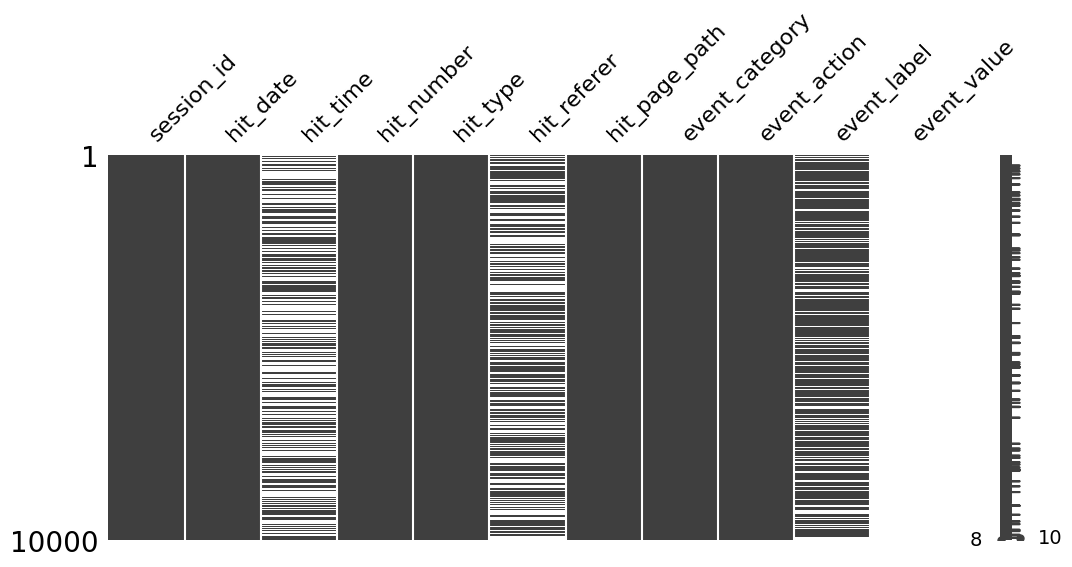

In [14]:
_ = msno.matrix(df_ga_hits.sample(10000, random_state=42), figsize=(12, 5))

**Визуализация пропусков в таблице `ga_sessions`**

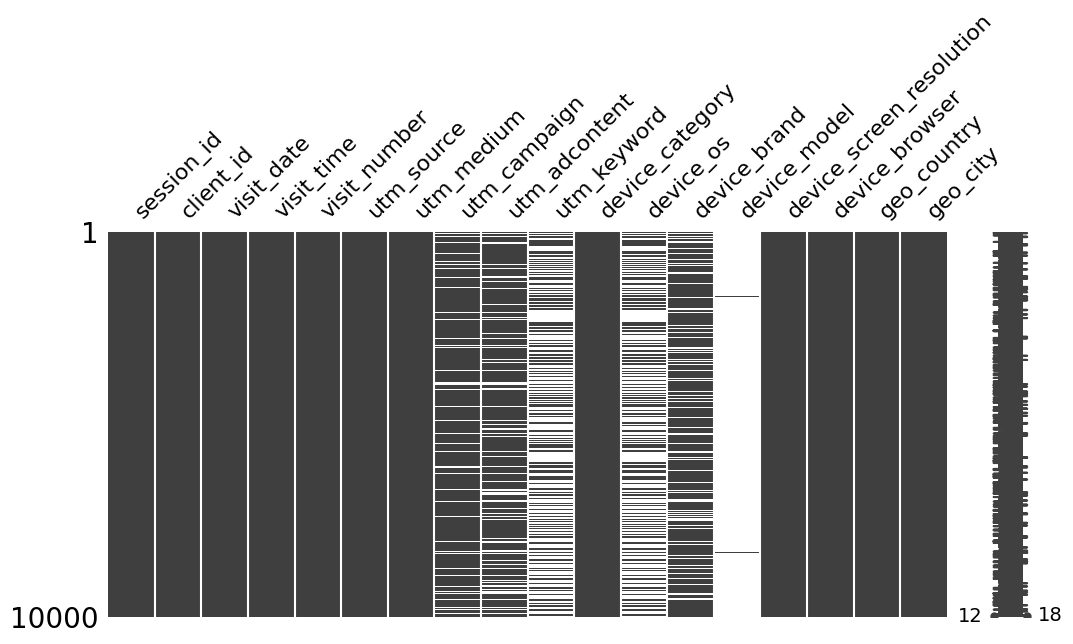

In [15]:
_ = msno.matrix(df_ga_sessions.sample(10000, random_state=42), figsize=(12, 5))

### 5.5 Дубликаты

In [16]:
print('Количество полных дубликатов в таблице ga_hits:')
df_ga_hits.duplicated().sum()

Количество полных дубликатов в таблице ga_hits:


np.int64(0)

In [17]:
print('Процент полных дубликатов в таблице ga_hits:')
round(df_ga_hits.duplicated().mean() * 100, 2)

Процент полных дубликатов в таблице ga_hits:


np.float64(0.0)

In [18]:
print('Вывод всех дубликатов в таблице ga_hits:')
df_ga_hits[df_ga_hits.duplicated()]

Вывод всех дубликатов в таблице ga_hits:


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value


In [19]:
print('Количество полных дубликатов в таблице ga_sessions:')
df_ga_sessions.duplicated().sum()

Количество полных дубликатов в таблице ga_sessions:


np.int64(0)

In [20]:
print('Процент полных дубликатов в таблице ga_sessions:')
round(df_ga_sessions.duplicated().mean() * 100, 2)

Процент полных дубликатов в таблице ga_sessions:


np.float64(0.0)

In [21]:
print('Вывод всех дубликатов в таблице ga_sessions:')
df_ga_sessions[df_ga_sessions.duplicated()]

Вывод всех дубликатов в таблице ga_sessions:


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city


### 5.6 Проверка ключевых значений и уникальности session_id

In [22]:
print(
    'Количество уникальных session_id:', df_ga_sessions['session_id'].nunique()
)
print('Количество строк в ga_sessions:', df_ga_sessions.shape[0])

Количество уникальных session_id: 1860042
Количество строк в ga_sessions: 1860042


In [23]:
print('Распределение по типам устройств:')
display(df_ga_sessions['device_category'].value_counts().to_frame())

print('Распределение по странам:')
display(df_ga_sessions['geo_country'].value_counts().head(20).to_frame())

print('Распределение по городам:')
display(df_ga_sessions['geo_city'].value_counts().head(20).to_frame())

print('Распределение по типам привлечения:')
display(df_ga_sessions['utm_medium'].value_counts().to_frame())

print('Распределение по браузерам:')
display(df_ga_sessions['device_browser'].value_counts().head(20).to_frame())

Распределение по типам устройств:


,count
device_category,
mobile,1474871
desktop,366863
tablet,18308


Распределение по странам:


,count
geo_country,
Russia,1800565
United States,11784
Ukraine,9012
Ireland,4034
Belarus,3636
Sweden,2694
Kazakhstan,2279
Germany,2232
Turkey,1953


Распределение по городам:


,count
geo_city,
Moscow,805329
Saint Petersburg,296788
(not set),78172
Yekaterinburg,35788
Krasnodar,32243
Kazan,29531
Samara,24992
Nizhny Novgorod,22227
Ufa,21679


Распределение по типам привлечения:


,count
utm_medium,
banner,552272
cpc,434794
(none),300575
cpm,242083
referral,152050
organic,63034
email,29240
push,28035
stories,10582


Распределение по браузерам:


,count
device_browser,
Chrome,1013436
Safari,478562
YaBrowser,133311
Safari (in-app),69912
Android Webview,55369
Samsung Internet,47309
Opera,26817
Firefox,16588
Edge,16065


In [24]:
print('Распределение по типам событий:')
display(df_ga_hits['hit_type'].value_counts().to_frame())

print('Распределение по категориям событий:')
display(df_ga_hits['event_category'].value_counts().to_frame())

print('Топ-20 действий пользователей:')
display(df_ga_hits['event_action'].value_counts().head(20).to_frame())

print('Топ-20 страниц по количеству событий:')
display(df_ga_hits['hit_page_path'].value_counts().head(20).to_frame())

print('Количество уникальных session_id в ga_hits:')
display(df_ga_hits['session_id'].nunique())

Распределение по типам событий:


,count
hit_type,
event,15726470


Распределение по категориям событий:


,count
event_category,
card_web,7456998
search_form,2423605
sub_page_view,1986074
sub_button_click,1073471
listing_ads,1040468
cars,358915
sap_search_form,356596
quiz,263134
auth,189373


Топ-20 действий пользователей:


,count
event_action,
view_card,3558985
view_new_card,3551009
sub_landing,1798117
go_to_car_card,973666
sub_view_cars_click,791515
search_form_region,512069
search_form_search_btn,433748
sap_search_form_cost_to,356596
showed_number_ads,326274


Топ-20 страниц по количеству событий:


,count
hit_page_path,
podpiska.sberauto.com/,2793639
sberauto.com/cars?city=1&rental_page=rental_only&rental_car=rental_only&city=18,1103484
sberauto.com/cars?utm_source_initial=sbol&utm_medium_initial=banner&utm_campaign_initial=LEoPHuyFvzoNfnzGgfcd&utm_content_initial=vCIpmpaGBnIQhyYNkXqp&city=1&rental_page=rental_only&rental_car=rental_only&city=18,754215
sberauto.com/cars/f28947a1?rental_page=rental_car,264878
sberauto.com/cars/bf24b977?rental_page=rental_car,263966
sberauto.com/cars?utm_source_initial=sbol&utm_medium_initial=banner&utm_campaign_initial=LEoPHuyFvzoNfnzGgfcd&city=1&rental_page=rental_only&rental_car=rental_only&city=18,257588
sberauto.com/cars?city=1&city=18&rental_page=rental_only&rental_car=rental_only&page=1,199098
sberauto.com/cars/bfc21661?rental_page=rental_car,187602
sberauto.com/cars/2fc745ed?rental_page=rental_car,168387


Количество уникальных session_id в ga_hits:


1734610

In [25]:
print('Дата и время визита в ga_sessions:')
display(df_ga_sessions[['visit_date', 'visit_time']].head())

print('Дата и время события в ga_hits:')
display(df_ga_hits[['hit_date', 'hit_time']].head())

Дата и время визита в ga_sessions:


,visit_date,visit_time
0,2021-11-24,14:36:32
1,2021-11-14,08:21:30
2,2021-12-28,02:42:06
3,2021-05-29,05:00:00
4,2021-05-29,05:00:00


Дата и время события в ga_hits:


,hit_date,hit_time
0,2021-12-23,597864.0
1,2021-12-23,597331.0
2,2021-12-23,796252.0
3,2021-12-23,934292.0
4,2021-12-23,768741.0


### Вывод по первичному осмотру данных

Объём данных в обеих таблицах достаточно большой: таблица `ga_sessions` содержит **1 860 042** строки и **18** столбцов, а таблица `ga_hits` - **15 726 470** строк и **11** столбцов. То, что в `ga_hits` строк значительно больше, чем в `ga_sessions`, объясняется структурой данных: одна строка в `ga_sessions` соответствует одному визиту пользователя на сайт, а одна строка в `ga_hits` - одному событию внутри визита. Поэтому в рамках одной сессии может быть несколько событий.

По результатам первичного осмотра видно, что часть признаков требует дальнейшей обработки. В таблице `ga_hits` признаки `hit_date` и `hit_time` необходимо будет привести к более удобным типам данных для дальнейшего анализа. В таблице `ga_sessions` аналогично потребуется обработать признаки `visit_date` и `visit_time`.

В обеих таблицах обнаружены пропуски. В `ga_hits` наибольшее количество пропусков содержится в колонках `event_value`, `hit_time`, `hit_referer` и `event_label`. В `ga_sessions` больше всего пропусков в колонках `device_model`, `utm_keyword`, `device_os`, `device_brand`, `utm_adcontent` и `utm_campaign`. Решение об удалении, сохранении или обработке этих признаков будет принято на этапе предобработки данных.

Полные дубликаты в таблицах `ga_hits` и `ga_sessions` не обнаружены.

Количество уникальных `session_id` в таблице `ga_sessions` совпадает с количеством строк, значит каждая строка соответствует отдельной сессии. В таблице `ga_hits` повторение `session_id` является ожидаемым, так как одна сессия может включать несколько событий.

Проверка ключевых категориальных признаков показала, что `device_category`, `utm_medium`, `geo_country`, `hit_type` и `event_action` содержат значения, важные для дальнейшего анализа. Эти признаки будут использоваться при сегментации трафика, определении целевых событий, расчёте CR и проверке гипотез.

## 6. Предобработка данных

### 6.1 Предобработка ga_sessions

In [26]:
# Создаём копию таблицы ga_sessions
sessions = df_ga_sessions.copy()

In [27]:
# Приводим visit_date к типу datetime
sessions['visit_date'] = pd.to_datetime(sessions['visit_date'])
sessions['visit_date'].apply(type).value_counts()

visit_date
<class 'pandas.Timestamp'>    1860042
Name: count, dtype: int64

In [28]:
# Приводим visit_time к формату времени
sessions['visit_time'] = pd.to_datetime(
    sessions['visit_time'], format='%H:%M:%S'
).dt.time
sessions['visit_time'].apply(type).value_counts()

visit_time
<class 'datetime.time'>    1860042
Name: count, dtype: int64

In [29]:
# Удаляем колонки с высокой долей пропусков и низкой значимостью для анализа
sessions = sessions.drop(
    columns=['device_model', 'utm_keyword', 'device_os'], errors='ignore'
)
sessions.columns

Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'device_category', 'device_brand', 'device_screen_resolution',
       'device_browser', 'geo_country', 'geo_city'],
      dtype='str')

In [30]:
# Заполняем пропуски в категориальных признаках
cols_to_fill = ['device_brand', 'utm_adcontent', 'utm_campaign', 'utm_source']
sessions[cols_to_fill] = sessions[cols_to_fill].fillna('unknown')

# Приводим разные варианты отсутствующих значений к единой категории unknown
missing_like_values = ['(not set)', 'not set', 'none', 'None', 'nan', 'NaN']
sessions[cols_to_fill] = sessions[cols_to_fill].replace(
    missing_like_values, 'unknown'
)

# Приводим значения utm_medium к нижнему регистру
sessions['utm_medium'] = sessions['utm_medium'].str.strip().str.lower()

# Создаём очищенную версию признака geo_city для географического анализа
sessions['geo_city_clean'] = sessions['geo_city']

# Приводим неинтерпретируемые значения городов к unknown
invalid_city_mask = sessions['geo_city_clean'].str.fullmatch(
    r'\d+', na=False
) | sessions['geo_city_clean'].isin(['(not set)', 'unknown'])

sessions.loc[invalid_city_mask, 'geo_city_clean'] = 'unknown'

# Проверяем значения в признаках, где были заполнены пропуски
print('Топ-10 значений utm_campaign:')
display(sessions['utm_campaign'].value_counts().head(10).to_frame())

print('Топ-10 значений utm_adcontent:')
display(sessions['utm_adcontent'].value_counts().head(10).to_frame())

print('Топ-10 значений device_brand:')
display(sessions['device_brand'].value_counts().head(10).to_frame())

print('Топ-10 значений utm_source:')
display(sessions['utm_source'].value_counts().head(10).to_frame())

Топ-10 значений utm_campaign:


,count
utm_campaign,
LTuZkdKfxRGVceoWkVyg,463481
LEoPHuyFvzoNfnzGgfcd,324044
FTjNLDyTrXaWYgZymFkV,247360
unknown,219603
gecBYcKZCPMcVYdSSzKP,134042
TmThBvoCcwkCZZUWACYq,26597
XHNUiSKKGTEpSAlaVMFQ,24524
okTXSMadDkjvntEHzIjp,24511
SgIUDYUKnyWHVowUOqid,22841


Топ-10 значений utm_adcontent:


,count
utm_adcontent,
JNHcPlZPxEMWDnRiyoBf,1006599
unknown,335615
vCIpmpaGBnIQhyYNkXqp,181048
xhoenQgDQsgfEPYNPwKO,113072
PkybGvWbaqORmxjNunqZ,60316
LLfCasrxQzJIyuldcuWy,24222
TuyPWsGQruPMpKvRxeBF,18189
UxrnyMlRBSOhOjytXnMG,13583
dUuXlWzvmhDSyclWRhNP,10280


Топ-10 значений device_brand:


,count
device_brand,
Apple,551088
unknown,384723
Samsung,332194
Xiaomi,288367
Huawei,185853
Realme,19058
OPPO,13504
Vivo,11740
OnePlus,9965


Топ-10 значений utm_source:


,count
utm_source,
ZpYIoDJMcFzVoPFsHGJL,578290
fDLlAcSmythWSCVMvqvL,300575
kjsLglQLzykiRbcDiGcD,266354
MvfHsxITijuriZxsqZqt,186199
BHcvLfOaCWvWTykYqHVe,116320
bByPQxmDaMXgpHeypKSM,102287
QxAxdyPLuQMEcrdZWdWb,51415
aXQzDWsJuGXeBXexNHjc,31152
jaSOmLICuBzCFqHfBdRg,29241


### 6.2 Предобработка ga_hits

In [31]:
# Создаём копию таблицы ga_hits
hits = df_ga_hits.copy()

In [32]:
# Удаляем неключевые колонки с высокой долей пропусков и
# неинформативный признак hit_type
hits = hits.drop(
    columns=[
        'event_value',
        'hit_time',
        'hit_referer',
        'event_label',
        'hit_type',
    ],
    errors='ignore',
)

hits.columns

Index(['session_id', 'hit_date', 'hit_number', 'hit_page_path',
       'event_category', 'event_action'],
      dtype='str')

In [33]:
# Приводим hit_date к типу datetime
hits['hit_date'] = pd.to_datetime(hits['hit_date'])
hits['hit_date'].apply(type).value_counts()

hit_date
<class 'pandas.Timestamp'>    15726470
Name: count, dtype: int64

### 6.3 Итоговая проверка после предобработки

In [34]:
# Функция для быстрой проверки состояния таблицы после обработки
def check_data(df, name):
    print(f'Проверка таблицы {name}')
    print('-' * 100)

    print('Размер таблицы:')
    display(df.shape)

    print('\nКолонки:')
    display(df.columns)

    print('\nИнформация о типах данных:')
    df.info()

    print('\nКоличество пропусков:')
    display(df.isna().sum().sort_values(ascending=False))

    print('\nКоличество полных дубликатов:')
    display(df.duplicated().sum())

In [35]:
check_data(sessions, 'sessions')

Проверка таблицы sessions
----------------------------------------------------------------------------------------------------
Размер таблицы:


(1860042, 16)


Колонки:


Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'device_category', 'device_brand', 'device_screen_resolution',
       'device_browser', 'geo_country', 'geo_city', 'geo_city_clean'],
      dtype='str')


Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 16 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   session_id                str           
 1   client_id                 str           
 2   visit_date                datetime64[us]
 3   visit_time                object        
 4   visit_number              int64         
 5   utm_source                str           
 6   utm_medium                str           
 7   utm_campaign              str           
 8   utm_adcontent             str           
 9   device_category           str           
 10  device_brand              str           
 11  device_screen_resolution  str           
 12  device_browser            str           
 13  geo_country               str           
 14  geo_city                  str           
 15  geo_city_clean            str           
dtypes: datetime64[us](1), int64(1), objec

session_id                  0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
device_category             0
device_brand                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
geo_city_clean              0
dtype: int64


Количество полных дубликатов:


np.int64(0)

In [36]:
check_data(hits, 'hits')

Проверка таблицы hits
----------------------------------------------------------------------------------------------------
Размер таблицы:


(15726470, 6)


Колонки:


Index(['session_id', 'hit_date', 'hit_number', 'hit_page_path',
       'event_category', 'event_action'],
      dtype='str')


Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 6 columns):
 #   Column          Dtype         
---  ------          -----         
 0   session_id      str           
 1   hit_date        datetime64[us]
 2   hit_number      int64         
 3   hit_page_path   str           
 4   event_category  str           
 5   event_action    str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 719.9 MB

Количество пропусков:


session_id        0
hit_date          0
hit_number        0
hit_page_path     0
event_category    0
event_action      0
dtype: int64


Количество полных дубликатов:


np.int64(225862)

### Вывод по предобработке данных

В рамках предобработки были созданы рабочие копии исходных таблиц `ga_sessions` и `ga_hits`, чтобы сохранить исходные данные без изменений.

В таблице `ga_sessions` признак `visit_date` был приведён к типу datetime, а `visit_time` - к формату времени. Колонки `device_model`, `utm_keyword` и `device_os` были удалены, так как содержали высокую долю пропусков и не являлись ключевыми для текущих задач анализа. Пропуски в категориальных признаках `device_brand`, `utm_adcontent`, `utm_campaign` и `utm_source` были заполнены значением `unknown`. Также разные варианты отсутствующих значений были приведены к единому виду `unknown`.

В таблице `ga_hits` были удалены неключевые признаки `event_value`, `hit_time`, `hit_referer`, `event_label` и `hit_type`. Колонка `event_value` была полностью пустой, а остальные удалённые признаки содержали значительную долю пропусков или не несли дополнительной аналитической информации для расчёта CR и проверки гипотез. После удаления части колонок появились дубликаты относительно оставшегося набора признаков, однако они не были удалены, так как могут соответствовать разным событиям, которые отличались по удалённым техническим признакам.

После предобработки в обеих рабочих таблицах отсутствуют пропуски в оставшихся признаках. Таблицы готовы для следующего этапа: формирования целевой метрики CR, определения целевых событий, агрегации событий до уровня сессии и объединения данных по `session_id`.

## 7. Формирование целевой метрики CR

### 7.1 Определение целевых событий

In [37]:
target_events = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click',
]

print('Топ-20 действий пользователей:')
display(hits['event_action'].value_counts().head(20).to_frame())

print('Количество целевых событий:')
display(
    hits[hits['event_action'].isin(target_events)]['event_action']
    .value_counts()
    .to_frame()
)

Топ-20 действий пользователей:


,count
event_action,
view_card,3558985
view_new_card,3551009
sub_landing,1798117
go_to_car_card,973666
sub_view_cars_click,791515
search_form_region,512069
search_form_search_btn,433748
sap_search_form_cost_to,356596
showed_number_ads,326274


Количество целевых событий:


,count
event_action,
sub_car_claim_click,37928
sub_open_dialog_click,25870
sub_submit_success,18439
sub_car_claim_submit_click,12359
sub_call_number_click,3653
sub_callback_submit_click,3074
sub_car_request_submit_click,2966
sub_custom_question_submit_click,619


### 7.2 Создание флага целевого события

In [38]:
# Создаём флаг целевого события
hits['is_target_event'] = hits['event_action'].isin(target_events).astype(int)
print(hits['is_target_event'].value_counts())
display(hits.head())

is_target_event
0    15621562
1      104908
Name: count, dtype: int64


,session_id,hit_date,hit_number,hit_page_path,event_category,event_action,is_target_event
0,5639623078712724064.1640254056.1640254056,2021-12-23,30,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,0
1,7750352294969115059.1640271109.1640271109,2021-12-23,41,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,0
2,885342191847998240.1640235807.1640235807,2021-12-23,49,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,0
3,142526202120934167.1640211014.1640211014,2021-12-23,46,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,0
4,3450086108837475701.1640265078.1640265078,2021-12-23,79,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,0


### 7.3 Агрегация событий до уровня сессии

In [39]:
# Агрегируем события до уровня сессии:
# если в сессии было хотя бы одно целевое событие, has_conversion = 1
session_conversions = (
    hits.groupby('session_id')['is_target_event']
    .max()
    .reset_index()
    .rename(columns={'is_target_event': 'has_conversion'})
)

display(session_conversions.head())

# Проверяем количество сессий с конверсией и без конверсии
display(session_conversions['has_conversion'].value_counts().to_frame())

# Проверяем, что каждая строка соответствует одной уникальной сессии
session_conversions['session_id'].nunique() == session_conversions.shape[0]

,session_id,has_conversion
0,1000009318903347362.1632663668.1632663668,0
1,1000010177899156286.1635013443.1635013443,0
2,1000013386240115915.1635402956.1635402956,0
3,1000017303238376207.1623489300.1623489300,0
4,1000020580299877109.1624943350.1624943350,0


,count
has_conversion,
0,1683850
1,50760


True

### 7.4 Объединение sessions и hits

In [40]:
# Объединяем sessions с таблицей конверсий
df_analysis = pd.merge(
    sessions, session_conversions, on='session_id', how='left'
)

# Проверяем пустые значения после объединения
display(
    df_analysis.isna().sum().sort_values(ascending=False).to_frame('count')
)

# Заполняем отсутствующие значения конверсии нулём
df_analysis['has_conversion'] = (
    df_analysis['has_conversion'].fillna(0).astype(int)
)

# Проверяем пустые значения после заполнения
display(
    df_analysis.isna().sum().sort_values(ascending=False).to_frame('count')
)

# Проверяем распределение флага конверсии
display(df_analysis['has_conversion'].value_counts().to_frame())

,count
has_conversion,127776
session_id,0
client_id,0
visit_time,0
visit_date,0
utm_source,0
utm_medium,0
utm_campaign,0
visit_number,0
utm_adcontent,0


,count
session_id,0
client_id,0
visit_date,0
visit_time,0
visit_number,0
utm_source,0
utm_medium,0
utm_campaign,0
utm_adcontent,0
device_category,0


,count
has_conversion,
0,1809728
1,50314


In [41]:
# Проверяем итоговую аналитическую таблицу
check_data(df_analysis, 'df_analysis')

# Проверяем, что одна строка соответствует одной сессии
print(df_analysis['session_id'].nunique() == df_analysis.shape[0])

# Проверяем распределение флага конверсии
display(df_analysis['has_conversion'].value_counts().to_frame('count'))

display(df_analysis.head())

Проверка таблицы df_analysis
----------------------------------------------------------------------------------------------------
Размер таблицы:


(1860042, 17)


Колонки:


Index(['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number',
       'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'device_category', 'device_brand', 'device_screen_resolution',
       'device_browser', 'geo_country', 'geo_city', 'geo_city_clean',
       'has_conversion'],
      dtype='str')


Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 17 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   session_id                str           
 1   client_id                 str           
 2   visit_date                datetime64[us]
 3   visit_time                object        
 4   visit_number              int64         
 5   utm_source                str           
 6   utm_medium                str           
 7   utm_campaign              str           
 8   utm_adcontent             str           
 9   device_category           str           
 10  device_brand              str           
 11  device_screen_resolution  str           
 12  device_browser            str           
 13  geo_country               str           
 14  geo_city                  str           
 15  geo_city_clean            str           
 16  has_conversion            int64      

session_id                  0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
device_category             0
device_brand                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
geo_city_clean              0
has_conversion              0
dtype: int64


Количество полных дубликатов:


np.int64(0)

True


,count
has_conversion,
0,1809728
1,50314


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,device_category,device_brand,device_screen_resolution,device_browser,geo_country,geo_city,geo_city_clean,has_conversion
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,mobile,Huawei,360x720,Chrome,Russia,Zlatoust,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,mobile,Samsung,385x854,Samsung Internet,Russia,Moscow,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,mobile,Huawei,360x720,Chrome,Russia,Krasnoyarsk,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,unknown,NOBKLgtuvqYWkXQHeYWM,mobile,Xiaomi,393x786,Chrome,Russia,Moscow,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,unknown,unknown,mobile,Xiaomi,393x786,Chrome,Russia,Moscow,Moscow,0


### 7.5 Расчёт общего CR

In [42]:
# Количество всех сессий
total_sessions = df_analysis.shape[0]

# Количество конверсионных сессий
converted_sessions = df_analysis['has_conversion'].sum()

# Общий CR
overall_cr = converted_sessions / total_sessions * 100

print('Всего сессий:', total_sessions)
print('Сессий с конверсией:', converted_sessions)
print(f'Общий CR: {overall_cr:.2f}%')

Всего сессий: 1860042
Сессий с конверсией: 50314
Общий CR: 2.70%


### Вывод по формированию целевой метрики CR

В таблице `hits` был создан флаг `is_target_event`, который показывает, является ли событие целевым. Затем события были агрегированы до уровня `session_id`: если в рамках сессии было хотя бы одно целевое событие, сессия получила признак `has_conversion = 1`, иначе `has_conversion = 0`.

После объединения агрегированной таблицы конверсий с `sessions` была получена итоговая аналитическая таблица `df_analysis`, где одна строка соответствует одной сессии. Всего в таблице содержится **1 860 042** сессии, из них **50 314** сессий являются конверсионными. Общий CR составил **2.70%**.

## 8. Разведочный анализ данных

### 8.1 Общая статистика по данным

In [43]:
period_days = (
    df_analysis['visit_date'].max() - df_analysis['visit_date'].min()
).days + 1

general_stats = pd.DataFrame(
    {
        'metric': [
            'Общее количество сессий',
            'Количество уникальных пользователей',
            'Количество сессий с конверсией',
            'Общий CR, %',
            'Минимальная дата визита',
            'Максимальная дата визита',
            'Длительность периода в днях',
            'Количество источников трафика',
            'Количество кампаний',
            'Количество городов',
            'Количество типов устройств',
        ],
        'value': [
            df_analysis.shape[0],
            df_analysis['client_id'].nunique(),
            df_analysis['has_conversion'].sum(),
            round(df_analysis['has_conversion'].mean() * 100, 2),
            df_analysis['visit_date'].min(),
            df_analysis['visit_date'].max(),
            period_days,
            df_analysis['utm_source'].nunique(),
            df_analysis['utm_campaign'].nunique(),
            df_analysis['geo_city'].nunique(),
            df_analysis['device_category'].nunique(),
        ],
    }
)

display(general_stats)

,metric,value
0,Общее количество сессий,1860042
1,Количество уникальных пользователей,1391719
2,Количество сессий с конверсией,50314
3,"Общий CR, %",2.7
4,Минимальная дата визита,2021-05-19 00:00:00
5,Максимальная дата визита,2021-12-31 00:00:00
6,Длительность периода в днях,227
7,Количество источников трафика,294
8,Количество кампаний,413
9,Количество городов,2548


**Вывод по общей статистике**

Итоговая аналитическая таблица содержит **1 860 042** сессии и **1 391 719** уникальных пользователей. Из всех сессий **50 314** завершились целевым действием, общий CR составил **2.7%**. Данные охватывают период с **19 мая 2021 года** по **31 декабря 2021 года**. В таблице представлены **294** источника трафика, **413** кампаний, **2548** городов и **3** типа устройств, что позволяет дальше анализировать трафик и конверсию по ключевым сегментам.

### 8.2 Распределение ключевых числовых признаков

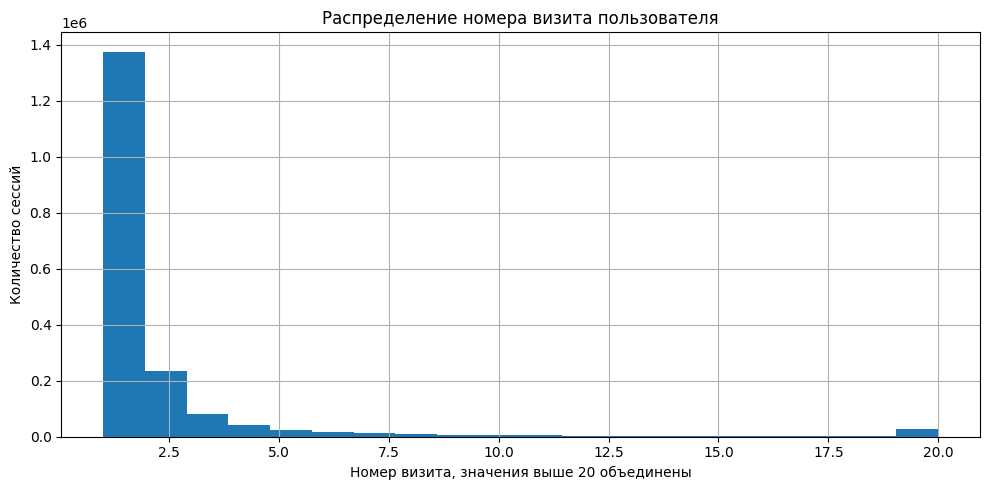

In [44]:
# Распределение номера визита пользователя
plt.figure(figsize=(10, 5))
df_analysis['visit_number'].clip(upper=20).hist(bins=20)
plt.title('Распределение номера визита пользователя')
plt.xlabel('Номер визита, значения выше 20 объединены')
plt.ylabel('Количество сессий')
plt.tight_layout()
plt.show()

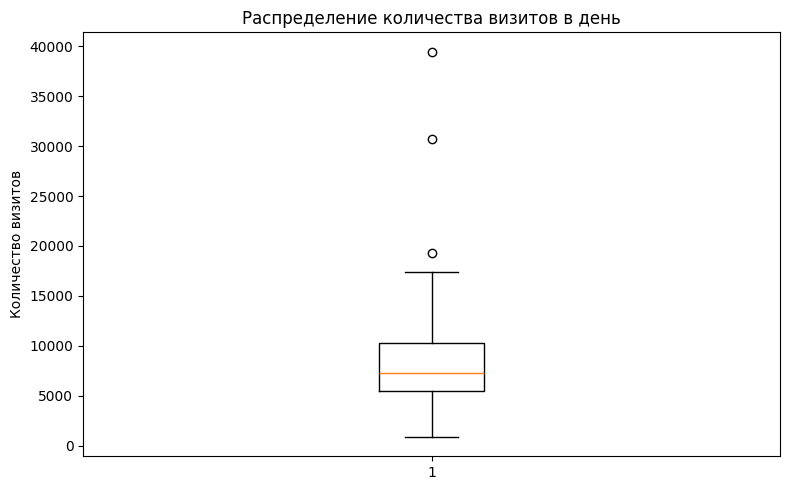

In [45]:
# Распределение количества визитов по дням
daily_visits = df_analysis.groupby('visit_date').size()

plt.figure(figsize=(8, 5))
plt.boxplot(daily_visits)
plt.title('Распределение количества визитов в день')
plt.ylabel('Количество визитов')
plt.tight_layout()
plt.show()

**Вывод по распределению ключевых числовых признаков**

Распределение номера визита имеет длинный правый хвост: большинство сессий приходится на первые визиты пользователей, а большие значения `visit_number` встречаются значительно реже. Это означает, что основная часть аудитории приходит на сайт 1-2 раза, а повторные визиты с большим номером встречаются редко.

Boxplot количества визитов в день показывает, что в данных есть отдельные дни с аномально высоким трафиком. Такие значения не удаляются, так как они могут отражать реальные всплески посещаемости: рекламные кампании, акции или другие внешние факторы. Для дальнейшего анализа они учитываются как часть поведения пользователей.

В рамках текущего анализа эти признаки используются для понимания структуры данных, но не являются основными признаками для проверки гипотез и бизнес-выводов. Основной анализ строится вокруг CR, источников трафика, устройств, регионов, автомобилей и social traffic.

### 8.3 Общая динамика визитов

In [46]:
# Проверяем тип visit_date
display(df_analysis['visit_date'].dtype)

# Считаем количество визитов по датам
visits_by_date = (
    df_analysis.groupby('visit_date')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('visit_date')
)

display(visits_by_date.head())

# День с максимальным количеством визитов
max_visits_day = visits_by_date.loc[visits_by_date['sessions_count'].idxmax()]

# День с минимальным количеством визитов
min_visits_day = visits_by_date.loc[visits_by_date['sessions_count'].idxmin()]

display(max_visits_day.to_frame().T)
display(min_visits_day.to_frame().T)

dtype('<M8[us]')

,visit_date,sessions_count
0,2021-05-19,877
1,2021-05-21,1110
2,2021-05-22,986
3,2021-05-23,1246
4,2021-05-24,39453


,visit_date,sessions_count
4,2021-05-24 00:00:00,39453


,visit_date,sessions_count
0,2021-05-19 00:00:00,877


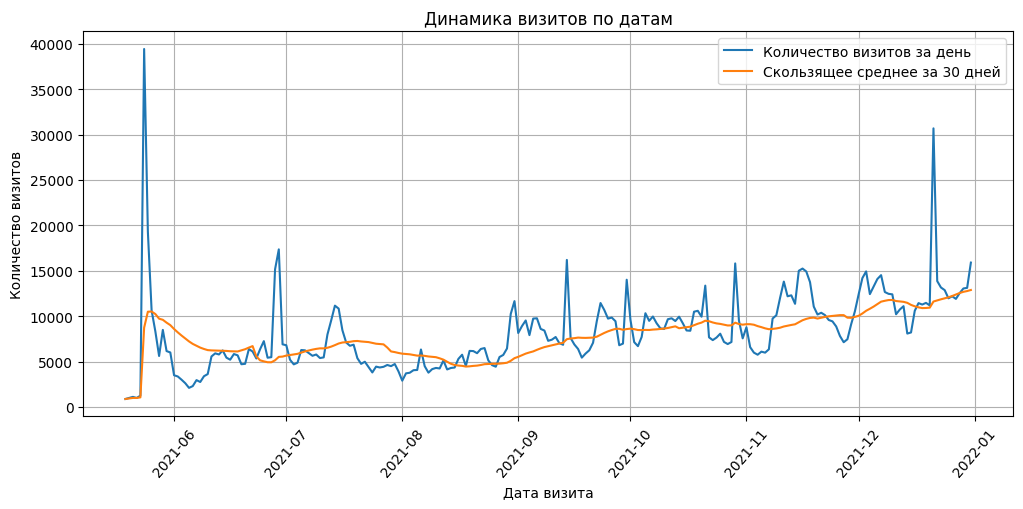

In [47]:
# Считаем скользящее среднее за 30 дней
visits_by_date['sessions_rolling_30'] = (
    visits_by_date['sessions_count'].rolling(window=30, min_periods=1).mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    visits_by_date['visit_date'],
    visits_by_date['sessions_count'],
    label='Количество визитов за день',
)

plt.plot(
    visits_by_date['visit_date'],
    visits_by_date['sessions_rolling_30'],
    label='Скользящее среднее за 30 дней',
)

plt.title('Динамика визитов по датам')
plt.xlabel('Дата визита')
plt.ylabel('Количество визитов')
plt.xticks(rotation=50)
plt.grid(True)
plt.legend()
plt.show()

**Вывод по динамике визитов**

Динамика визитов по датам распределена неравномерно. Максимальное количество визитов зафиксировано **24 мая 2021 года** - **39 453 визита**. Минимальное количество визитов наблюдается **19 мая 2021 года** - **877 визитов**. При этом в соседние дни значения также остаются относительно низкими, поэтому минимум скорее отражает низкий уровень трафика в начале наблюдаемого периода.

После сильного майского пика 30-дневное скользящее среднее снижается и стабилизируется на более низком уровне. Это связано с тем, что резкий всплеск в начале периода заметно влияет на среднее значение. Начиная примерно с середины августа, скользящее среднее показывает постепенный рост среднего дневного количества визитов. К концу периода уровень трафика становится заметно выше, чем летом. Также видны отдельные резкие пики в конце июня и в декабре, которые могут быть связаны с рекламными активностями, сезонностью или другими внешними факторами.

### 8.4 Распределение трафика по источникам

In [48]:
# Считаем количество визитов по источникам трафика
traffic_by_source = (
    df_analysis.groupby('utm_source')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю источника от общего количества визитов
traffic_by_source['sessions_share_%'] = (
    traffic_by_source['sessions_count'] / df_analysis.shape[0] * 100
).round(2)

display(traffic_by_source.head(10))

,utm_source,sessions_count,sessions_share_%
153,ZpYIoDJMcFzVoPFsHGJL,578290,31.09
183,fDLlAcSmythWSCVMvqvL,300575,16.16
217,kjsLglQLzykiRbcDiGcD,266354,14.32
79,MvfHsxITijuriZxsqZqt,186199,10.01
5,BHcvLfOaCWvWTykYqHVe,116320,6.25
161,bByPQxmDaMXgpHeypKSM,102287,5.50
99,QxAxdyPLuQMEcrdZWdWb,51415,2.76
158,aXQzDWsJuGXeBXexNHjc,31152,1.67
212,jaSOmLICuBzCFqHfBdRg,29241,1.57
107,RmEBuqrriAfAVsLQQmhk,28055,1.51


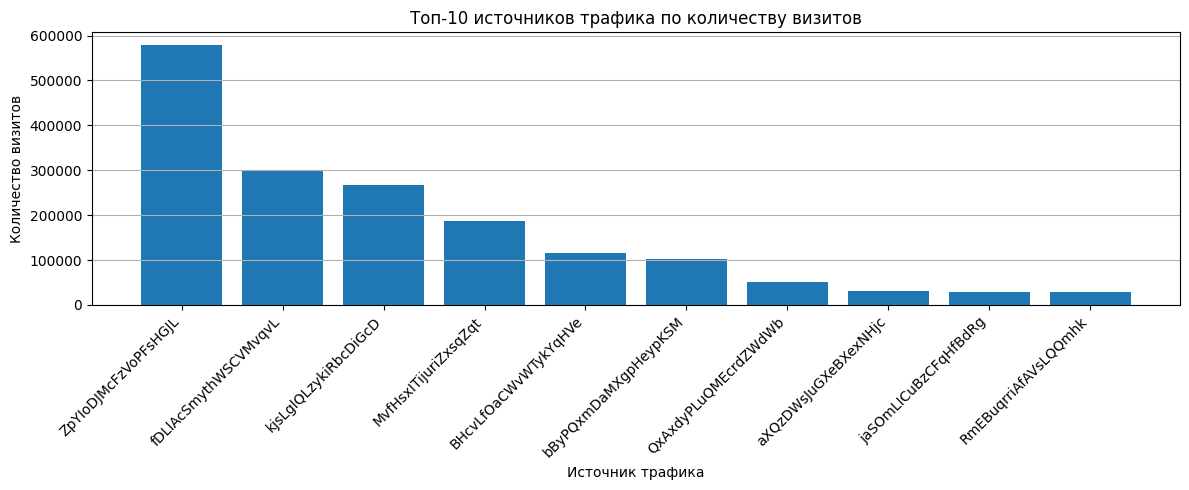

In [49]:
# Выбираем топ-10 источников по количеству визитов
top_sources = traffic_by_source.head(10)

plt.figure(figsize=(12, 5))

plt.bar(top_sources['utm_source'], top_sources['sessions_count'])

plt.title('Топ-10 источников трафика по количеству визитов')
plt.xlabel('Источник трафика')
plt.ylabel('Количество визитов')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [50]:
# Считаем количество визитов по типам привлечения
traffic_by_medium = (
    df_analysis.groupby('utm_medium')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю типа привлечения от общего количества визитов
traffic_by_medium['sessions_share_%'] = (
    traffic_by_medium['sessions_count'] / df_analysis.shape[0] * 100
).round(2)

display(traffic_by_medium.head(10))

,utm_medium,sessions_count,sessions_share_%
4,banner,552272,29.69
12,cpc,434794,23.38
0,(none),300575,16.16
13,cpm,242123,13.02
40,referral,152050,8.17
30,organic,63034,3.39
17,email,29240,1.57
36,push,28035,1.51
48,stories,10582,0.57
14,cpv,8022,0.43


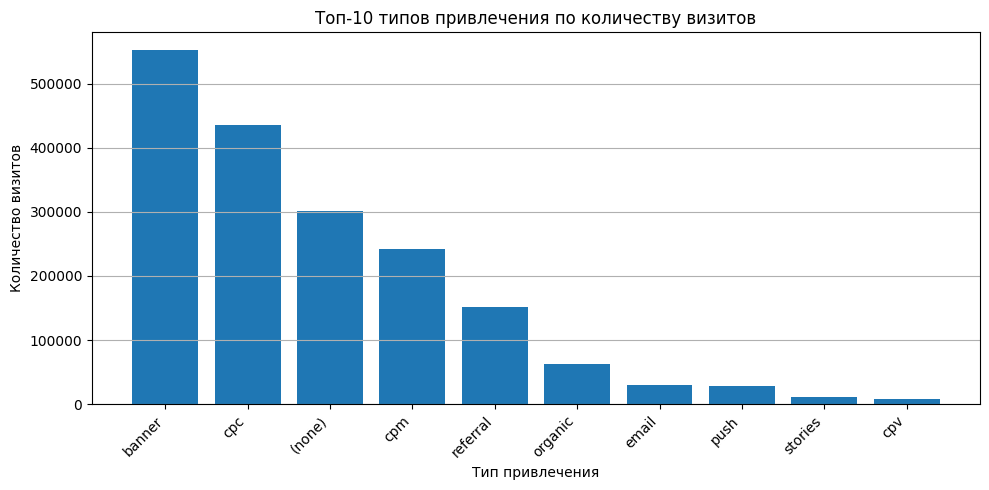

In [51]:
# Выбираем топ-10 типов привлечения по количеству визитов
top_medium = traffic_by_medium.head(10)

plt.figure(figsize=(10, 5))

plt.bar(top_medium['utm_medium'], top_medium['sessions_count'])

plt.title('Топ-10 типов привлечения по количеству визитов')
plt.xlabel('Тип привлечения')
plt.ylabel('Количество визитов')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по распределению трафика по источникам**

Основная часть трафика сосредоточена в нескольких источниках. Значения `utm_source` выглядят как закодированные идентификаторы, поэтому по ним можно сравнивать объём трафика, но сложно интерпретировать реальные названия каналов.

Дополнительно был рассмотрен признак `utm_medium`, который показывает тип привлечения. Наибольшее количество визитов приходится на несколько основных типов привлечения, среди которых `banner`, `cpc`, `(none)` и `cpm`. Значение `(none)` означает отсутствие явно заданного типа привлечения, но в рамках методички относится к органическому трафику.

На данном этапе анализируется только объём трафика. Эффективность источников и типов привлечения будет оцениваться позже через CR.

### 8.5 Распределение трафика по типам устройств

In [52]:
# Считаем количество визитов по категориям устройств
traffic_by_device_category = (
    df_analysis.groupby('device_category')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю категории устройств от общего количества визитов
traffic_by_device_category['sessions_share_%'] = (
    traffic_by_device_category['sessions_count'] / df_analysis.shape[0] * 100
).round(2)

display(traffic_by_device_category)

,device_category,sessions_count,sessions_share_%
1,mobile,1474871,79.29
0,desktop,366863,19.72
2,tablet,18308,0.98


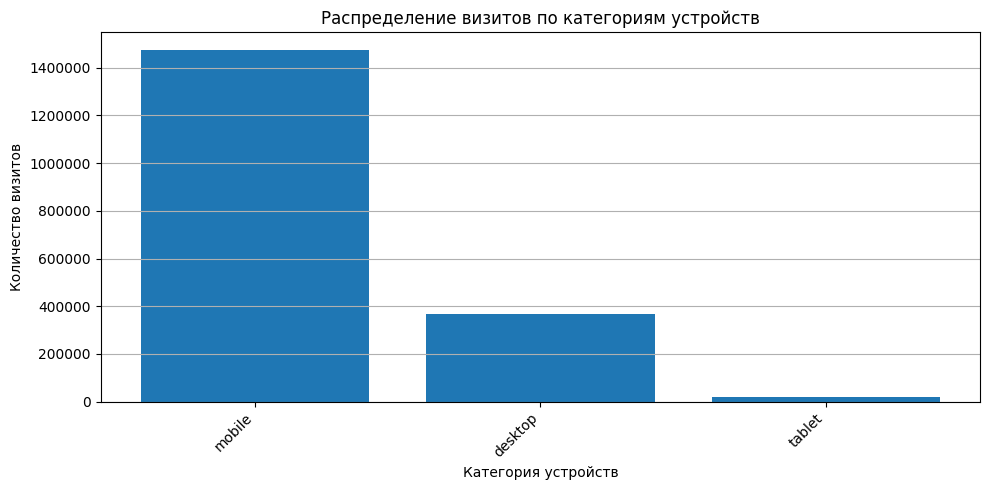

In [53]:
# Строим график распределения визитов по категориям устройств
plt.figure(figsize=(10, 5))

plt.bar(
    traffic_by_device_category['device_category'],
    traffic_by_device_category['sessions_count'],
)

plt.title('Распределение визитов по категориям устройств')
plt.xlabel('Категория устройств')
plt.ylabel('Количество визитов')
plt.xticks(rotation=45, ha='right')

# Показываем значения на оси Y обычными числами, без 1e6
plt.ticklabel_format(style='plain', axis='y')

plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по распределению трафика по типам устройств**

Основная часть визитов приходится на `mobile`, поэтому мобильные устройства являются главным источником трафика по категории устройств. `desktop` даёт заметно меньший объём визитов, а `tablet` занимает минимальную долю. Это показывает, что сайт в основном используется с мобильных устройств.

На данном этапе анализируется только объём трафика. Позже будет отдельно проверено, отличается ли мобильный и десктопный трафик по эффективности через CR.

### 8.6 Распределение трафика по городам

In [54]:
# Считаем количество визитов по городам
traffic_by_city = (
    df_analysis.groupby('geo_city')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю каждого города от общего количества визитов
traffic_by_city['sessions_share_%'] = (
    traffic_by_city['sessions_count'] / df_analysis.shape[0] * 100
).round(2)

display(traffic_by_city.head(10))

,geo_city,sessions_count,sessions_share_%
1434,Moscow,805329,43.30
1930,Saint Petersburg,296788,15.96
1,(not set),78172,4.20
2483,Yekaterinburg,35788,1.92
1110,Krasnodar,32243,1.73
1003,Kazan,29531,1.59
1949,Samara,24992,1.34
1546,Nizhny Novgorod,22227,1.19
2299,Ufa,21679,1.17
1585,Novosibirsk,21568,1.16


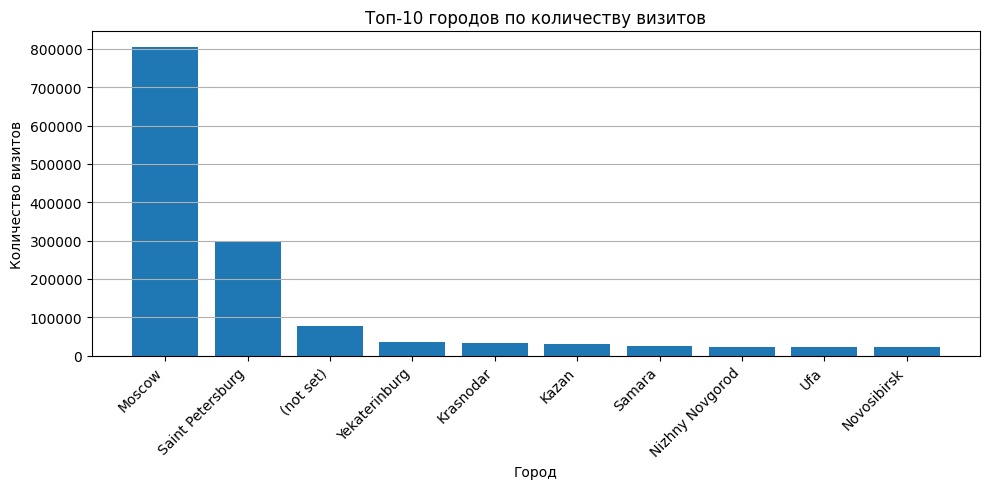

In [55]:
# Выбираем топ-10 городов по количеству визитов
top_cities = traffic_by_city.head(10)

# Строим график топ-10 городов по количеству визитов
plt.figure(figsize=(10, 5))

plt.bar(top_cities['geo_city'], top_cities['sessions_count'])

plt.title('Топ-10 городов по количеству визитов')
plt.xlabel('Город')
plt.ylabel('Количество визитов')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [56]:
# Считаем количество визитов по странам
traffic_by_country = (
    df_analysis.groupby('geo_country')
    .size()
    .reset_index(name='sessions_count')
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю страны от общего количества визитов
traffic_by_country['sessions_share_%'] = (
    traffic_by_country['sessions_count'] / df_analysis.shape[0] * 100
).round(2)

display(traffic_by_country.head(10))

,geo_country,sessions_count,sessions_share_%
123,Russia,1800565,96.80
157,United States,11784,0.63
154,Ukraine,9012,0.48
69,Ireland,4034,0.22
16,Belarus,3636,0.20
142,Sweden,2694,0.14
74,Kazakhstan,2279,0.12
52,Germany,2232,0.12
151,Turkey,1953,0.10
102,Netherlands,1549,0.08


**Вывод по распределению трафика по городам**

Основной объём трафика приходится на `Moscow` - **43.3%** визитов и `Saint Petersburg` - **15.96%** визитов. Категория `(not set)` занимает **4.2%**, то есть для части сессий город не был определён. Остальные города из топ-10 имеют заметно меньшие доли - каждый менее **2%** от общего трафика.

Дополнительно видно, что **96.8%** всех визитов приходится на `Russia`, поэтому дальнейший географический анализ логично проводить на уровне городов внутри России. На этом этапе анализируется только объём трафика, эффективность городов будет оцениваться позже через CR.

### 8.7 CR по источникам и типам привлечения

In [57]:
# Считаем CR по источникам трафика
cr_by_source = (
    df_analysis.groupby('utm_source')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
)

cr_by_source['cr_percent'] = (cr_by_source['cr_percent'] * 100).round(2)

display(cr_by_source.head())

,utm_source,sessions_count,conversions_count,cr_percent
0,AHgbtEjTEsiUMJouiDYS,26,0,0.0
1,ANoZJgYuPrWNkAAchryx,14,0,0.0
2,ArbfvYgWhqxkzywKqpQf,20,0,0.0
3,AuJjYKxJakEqFnCmyFtz,4,0,0.0
4,BAZCuyHZnaPrMGOMrcCQ,1,0,0.0


In [58]:
# Топ-10 источников по количеству визитов
display(cr_by_source.sort_values('sessions_count', ascending=False).head(10))

# Топ-10 источников по CR среди источников с достаточным количеством визитов
min_sessions = 1000

display(
    cr_by_source[cr_by_source['sessions_count'] >= min_sessions]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

# Топ-10 источников по количеству конверсий
display(
    cr_by_source.sort_values('conversions_count', ascending=False).head(10)
)

,utm_source,sessions_count,conversions_count,cr_percent
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.77
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.50
217,kjsLglQLzykiRbcDiGcD,266354,6293,2.36
79,MvfHsxITijuriZxsqZqt,186199,2249,1.21
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.34
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.43
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.73
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.86
212,jaSOmLICuBzCFqHfBdRg,29241,401,1.37
107,RmEBuqrriAfAVsLQQmhk,28055,139,0.50


,utm_source,sessions_count,conversions_count,cr_percent
241,oZCzWSykfixnjMPDNjSU,3143,260,8.27
6,BKeImrJuRDZcHiSSTdzm,1464,98,6.69
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.86
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.43
23,DnEUulZAecfGPvdtZBYS,1420,76,5.35
218,klTrhUaShgnjIbaPmqjc,1197,42,3.51
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.50
128,WEXkMlsnJodrzBgKJBpG,1003,35,3.49
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.34
60,KgicpPxiEQfzPlPwQZJq,1761,55,3.12


,utm_source,sessions_count,conversions_count,cr_percent
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.77
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.50
217,kjsLglQLzykiRbcDiGcD,266354,6293,2.36
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.43
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.34
79,MvfHsxITijuriZxsqZqt,186199,2249,1.21
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.86
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.73
212,jaSOmLICuBzCFqHfBdRg,29241,401,1.37
241,oZCzWSykfixnjMPDNjSU,3143,260,8.27


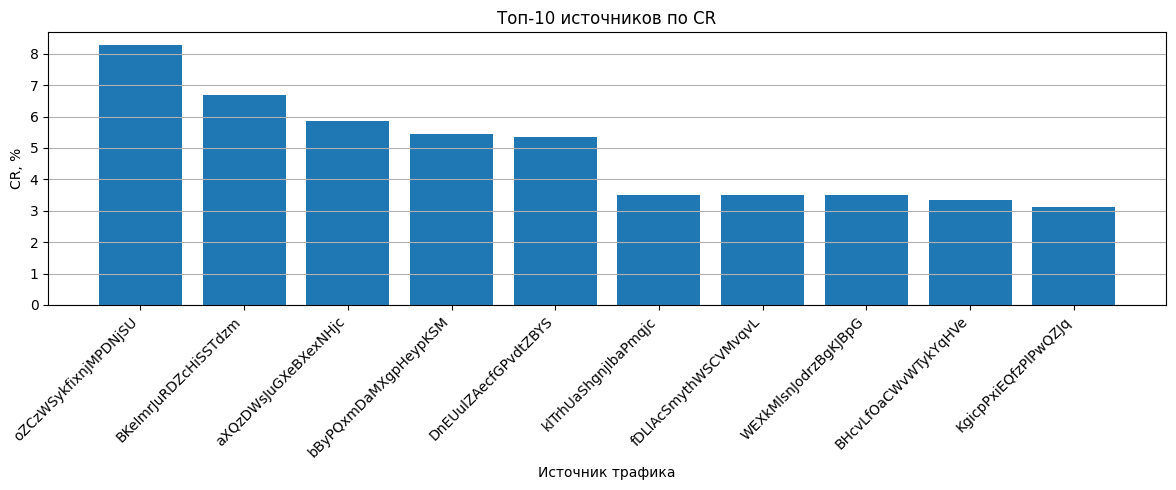

In [59]:
# График топ-10 источников по CR среди источников с достаточным объёмом трафика
top_sources_by_cr = (
    cr_by_source[cr_by_source['sessions_count'] >= min_sessions]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))

plt.bar(top_sources_by_cr['utm_source'], top_sources_by_cr['cr_percent'])

plt.title('Топ-10 источников по CR')
plt.xlabel('Источник трафика')
plt.ylabel('CR, %')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

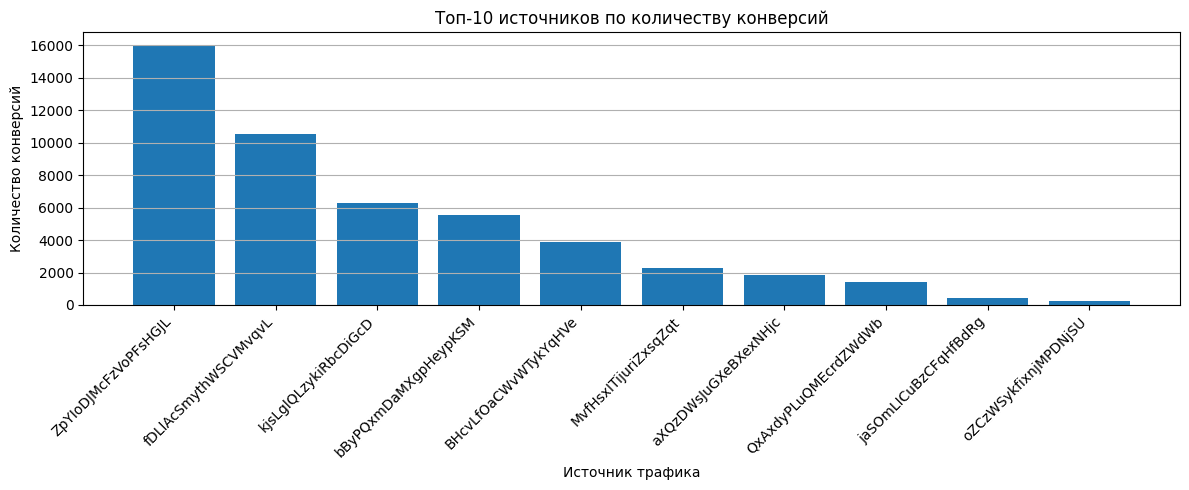

In [60]:
# Топ-10 источников по количеству конверсий
top_sources_by_conversions = cr_by_source.sort_values(
    'conversions_count', ascending=False
).head(10)

plt.figure(figsize=(12, 5))

plt.bar(
    top_sources_by_conversions['utm_source'],
    top_sources_by_conversions['conversions_count'],
)

plt.title('Топ-10 источников по количеству конверсий')
plt.xlabel('Источник трафика')
plt.ylabel('Количество конверсий')
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [61]:
# Считаем количество сессий, конверсий и CR по типам привлечения
cr_by_medium = (
    df_analysis.groupby('utm_medium')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
)

cr_by_medium['cr_percent'] = (cr_by_medium['cr_percent'] * 100).round(2)

display(cr_by_medium.head())

,utm_medium,sessions_count,conversions_count,cr_percent
0,(none),300575,10531,3.50
1,(not set),480,28,5.83
2,app,2836,11,0.39
3,article,17,0,0.00
4,banner,552272,15107,2.74


In [62]:
# Топ типов привлечения по количеству визитов
display(cr_by_medium.sort_values('sessions_count', ascending=False).head(10))

# Топ типов привлечения по CR среди типов с достаточным количеством визитов
min_sessions = 1000

display(
    cr_by_medium[cr_by_medium['sessions_count'] >= min_sessions]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

# Топ типов привлечения по количеству конверсий
display(
    cr_by_medium.sort_values('conversions_count', ascending=False).head(10)
)

,utm_medium,sessions_count,conversions_count,cr_percent
4,banner,552272,15107,2.74
12,cpc,434794,9529,2.19
0,(none),300575,10531,3.50
13,cpm,242123,2522,1.04
40,referral,152050,8181,5.38
30,organic,63034,2100,3.33
17,email,29240,401,1.37
36,push,28035,840,3.00
48,stories,10582,126,1.19
14,cpv,8022,115,1.43


,utm_medium,sessions_count,conversions_count,cr_percent
40,referral,152050,8181,5.38
44,smm,1985,87,4.38
0,(none),300575,10531,3.50
30,organic,63034,2100,3.33
11,cpa,4279,131,3.06
36,push,28035,840,3.00
4,banner,552272,15107,2.74
43,smartbanner,6794,179,2.63
33,post,2326,54,2.32
12,cpc,434794,9529,2.19


,utm_medium,sessions_count,conversions_count,cr_percent
4,banner,552272,15107,2.74
0,(none),300575,10531,3.50
12,cpc,434794,9529,2.19
40,referral,152050,8181,5.38
13,cpm,242123,2522,1.04
30,organic,63034,2100,3.33
36,push,28035,840,3.00
17,email,29240,401,1.37
43,smartbanner,6794,179,2.63
5,blogger_channel,8015,162,2.02


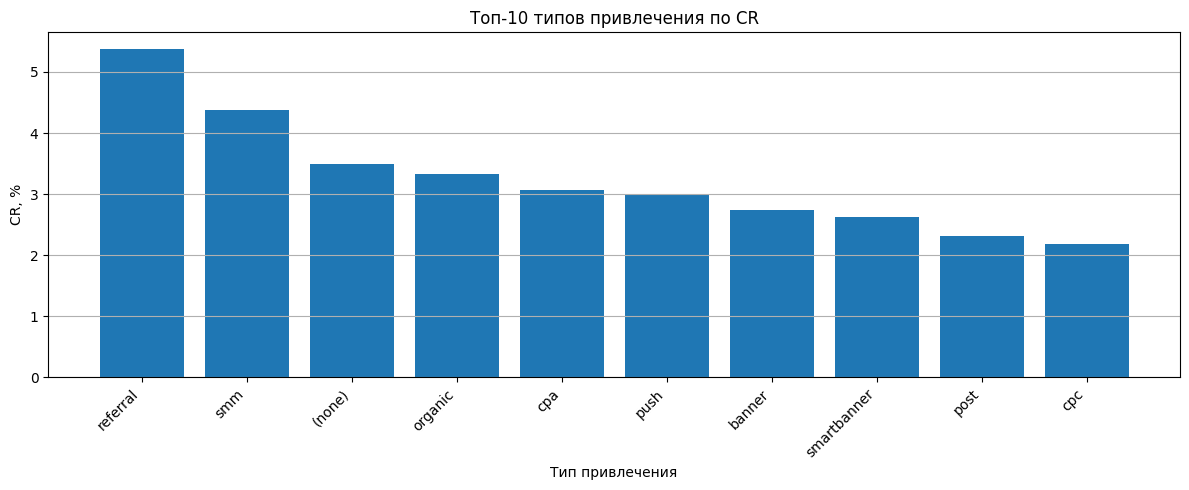

In [63]:
# График топ-10 типов привлечения по CR среди типов с достаточным объёмом трафика
top_mediums_by_cr = (
    cr_by_medium[cr_by_medium['sessions_count'] >= min_sessions]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))

plt.bar(top_mediums_by_cr['utm_medium'], top_mediums_by_cr['cr_percent'])

plt.title('Топ-10 типов привлечения по CR')
plt.xlabel('Тип привлечения')
plt.ylabel('CR, %')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

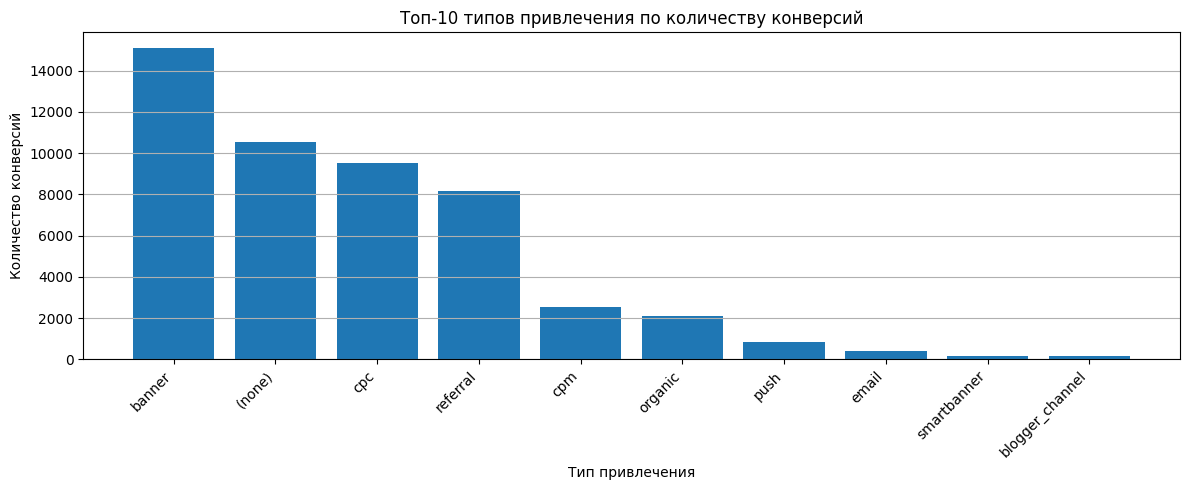

In [64]:
# Топ-10 типов привлечения по количеству конверсий
top_mediums_by_conversions = cr_by_medium.sort_values(
    'conversions_count', ascending=False
).head(10)

plt.figure(figsize=(12, 5))

plt.bar(
    top_mediums_by_conversions['utm_medium'],
    top_mediums_by_conversions['conversions_count'],
)

plt.title('Топ-10 типов привлечения по количеству конверсий')
plt.xlabel('Тип привлечения')
plt.ylabel('Количество конверсий')
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по CR источников и типов привлечения**

По источникам трафика видно, что самый большой объём визитов не всегда соответствует самому высокому CR. Источник `ZpYIoDJMcFzVoPFsHGJL` даёт наибольшее количество сессий и конверсий, но его CR составляет **2.77%**. При этом некоторые источники с меньшим объёмом трафика показывают более высокий CR: например, `oZCzWSykfixnjMPDNjSU` имеет CR **8.27%**, но только **3143** сессии.

С точки зрения баланса между объёмом и эффективностью выделяются источники `bByPQxmDaMXgpHeypKSM` и `aXQzDWsJuGXeBXexNHjc`: они имеют заметный объём трафика и высокий CR относительно крупных источников.

По типам привлечения наибольшее количество визитов дают `banner`, `cpc`, `(none)` и `cpm`. Самый высокий CR среди типов привлечения с достаточным объёмом трафика показывает `referral` - **5.38%**. При этом больше всего конверсий в абсолютном количестве дают `banner`, `(none)`, `cpc` и `referral`.

Таким образом, при оценке источников важно учитывать не только CR, но и объём трафика и количество конверсий. Источники с высоким CR, но малым количеством визитов, могут быть интересны для дальнейшего изучения, но не всегда дают большой вклад в общий результат.

### 8.8 CR по устройствам

In [65]:
# Считаем количество сессий, конверсий и CR по типам устройств
cr_by_device_category = (
    df_analysis.groupby('device_category')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
    .sort_values('sessions_count', ascending=False)
)

cr_by_device_category['cr_percent'] = (
    cr_by_device_category['cr_percent'] * 100
).round(2)

display(cr_by_device_category)

,device_category,sessions_count,conversions_count,cr_percent
1,mobile,1474871,38379,2.60
0,desktop,366863,11513,3.14
2,tablet,18308,422,2.31


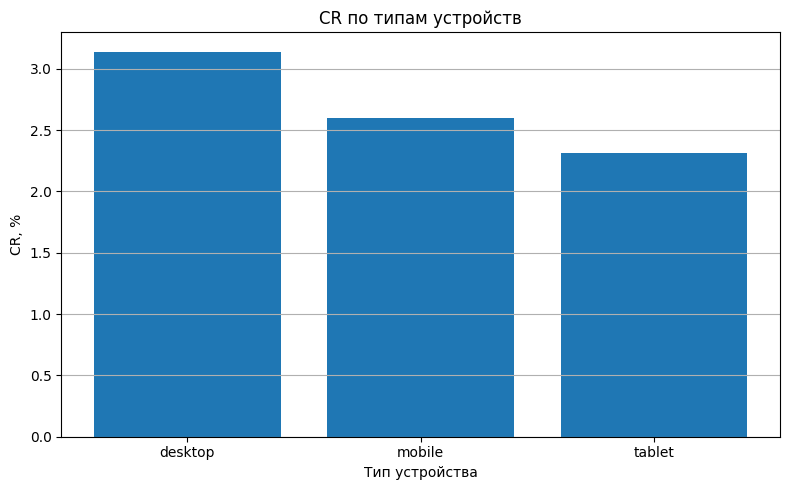

In [66]:
# Сортируем типы устройств по CR
device_category_by_cr = cr_by_device_category.sort_values(
    'cr_percent', ascending=False
)

# Строим график CR по типам устройств
plt.figure(figsize=(8, 5))

plt.bar(
    device_category_by_cr['device_category'],
    device_category_by_cr['cr_percent'],
)

plt.title('CR по типам устройств')
plt.xlabel('Тип устройства')
plt.ylabel('CR, %')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

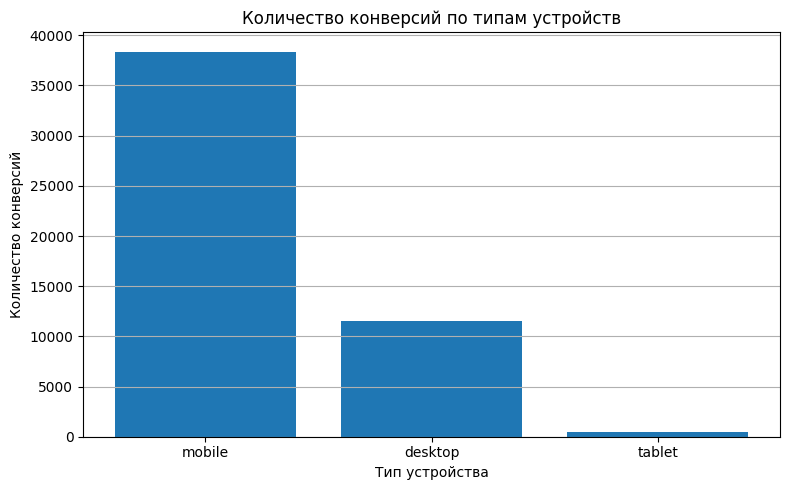

In [67]:
# Строим график количества конверсий по типам устройств
plt.figure(figsize=(8, 5))

plt.bar(
    cr_by_device_category['device_category'],
    cr_by_device_category['conversions_count'],
)

plt.title('Количество конверсий по типам устройств')
plt.xlabel('Тип устройства')
plt.ylabel('Количество конверсий')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по CR устройств**

По объёму трафика лидируют мобильные устройства: `mobile` даёт **1 474 871** сессию и **38 379** конверсий. Однако самый высокий CR показывает `desktop` - **3.14%**, тогда как у `mobile` CR составляет **2.60%**, а у `tablet` - **2.31%**.

Это означает, что мобильный трафик даёт основной вклад в абсолютное количество конверсий за счёт большого объёма, но десктопный трафик конвертируется эффективнее. В дальнейшем различие между `mobile` и `desktop` нужно будет проверить статистически в разделе проверки гипотез.

### 8.9 CR по городам и регионам

In [68]:
# Считаем количество сессий, конверсий и CR по городам
cr_by_city = (
    df_analysis.groupby('geo_city_clean')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
)

cr_by_city['cr_percent'] = (cr_by_city['cr_percent'] * 100).round(2)

display(cr_by_city.head())

,geo_city_clean,sessions_count,conversions_count,cr_percent
0,'s-Hertogenbosch,3,0,0.0
1,10th of Ramadan City,12,0,0.0
2,6th of October City,8,0,0.0
3,Aachen,4,0,0.0
4,Aalborg,1,0,0.0


In [69]:
# Топ-10 городов по количеству визитов
display(cr_by_city.sort_values('sessions_count', ascending=False).head(10))

# Топ-10 городов по CR среди городов с достаточным количеством визитов
min_sessions = 1000

top_cities_by_cr = (
    cr_by_city[
        (cr_by_city['geo_city_clean'] != 'unknown')
        & (cr_by_city['sessions_count'] >= min_sessions)
    ]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

display(top_cities_by_cr)

# Топ-10 городов по количеству конверсий
top_cities_by_conversions = (
    cr_by_city[cr_by_city['geo_city_clean'] != 'unknown']
    .sort_values('conversions_count', ascending=False)
    .head(10)
)

display(top_cities_by_conversions)

,geo_city_clean,sessions_count,conversions_count,cr_percent
1406,Moscow,805329,23629,2.93
1902,Saint Petersburg,296788,7113,2.40
2517,unknown,78465,1597,2.04
2455,Yekaterinburg,35788,887,2.48
1082,Krasnodar,32243,1081,3.35
975,Kazan,29531,1139,3.86
1921,Samara,24992,727,2.91
1518,Nizhny Novgorod,22227,559,2.51
2271,Ufa,21679,639,2.95
1557,Novosibirsk,21568,509,2.36


,geo_city_clean,sessions_count,conversions_count,cr_percent
550,Domodedovo,4038,263,6.51
1280,Makhachkala,2607,139,5.33
1450,Nalchik,1099,52,4.73
2354,Vladikavkaz,1149,54,4.70
2110,Stavropol,4377,180,4.11
975,Kazan,29531,1139,3.86
422,Cheboksary,2320,83,3.58
1055,Korolyov,4047,145,3.58
2055,Sochi,8972,316,3.52
1213,Lobnya,1984,68,3.43


,geo_city_clean,sessions_count,conversions_count,cr_percent
1406,Moscow,805329,23629,2.93
1902,Saint Petersburg,296788,7113,2.40
975,Kazan,29531,1139,3.86
1082,Krasnodar,32243,1081,3.35
2455,Yekaterinburg,35788,887,2.48
1921,Samara,24992,727,2.91
2271,Ufa,21679,639,2.95
1518,Nizhny Novgorod,22227,559,2.51
1557,Novosibirsk,21568,509,2.36
2252,Tula,15814,438,2.77


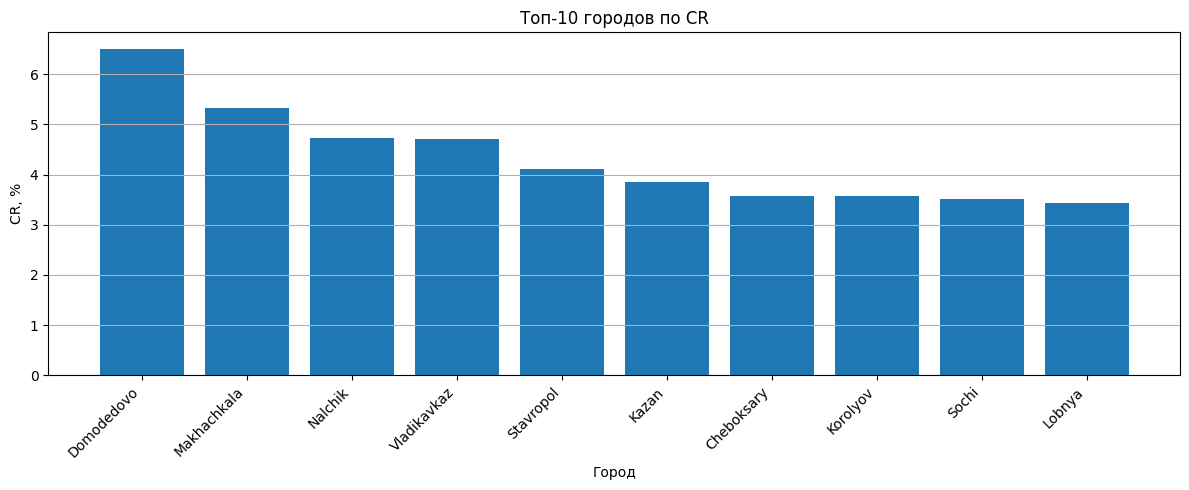

In [70]:
# Строим график топ-10 городов по CR
plt.figure(figsize=(12, 5))

plt.bar(top_cities_by_cr['geo_city_clean'], top_cities_by_cr['cr_percent'])

plt.title('Топ-10 городов по CR')
plt.xlabel('Город')
plt.ylabel('CR, %')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

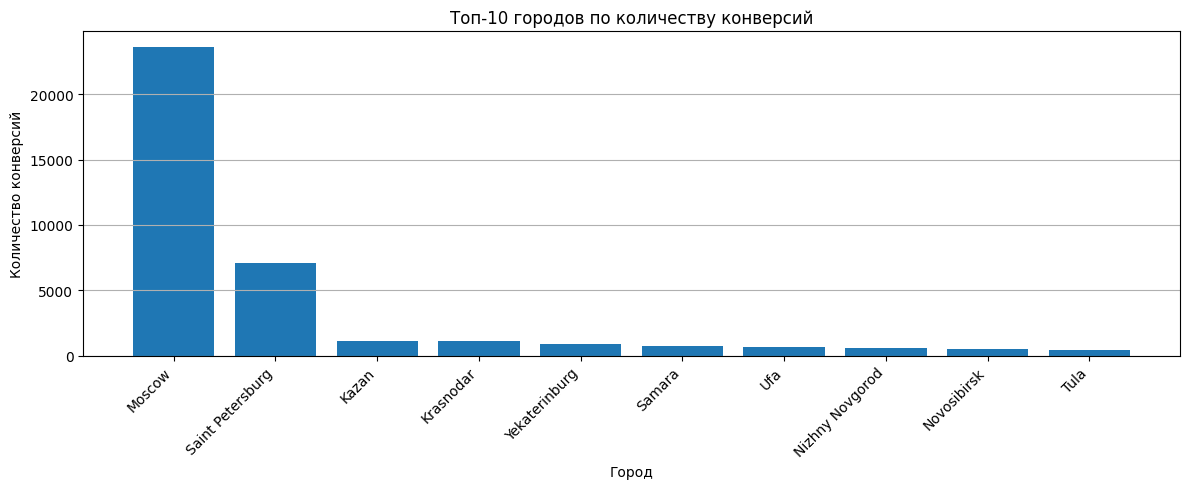

In [71]:
# Строим график топ-10 городов по количеству конверсий
plt.figure(figsize=(12, 5))

plt.bar(
    top_cities_by_conversions['geo_city_clean'],
    top_cities_by_conversions['conversions_count'],
)

plt.title('Топ-10 городов по количеству конверсий')
plt.xlabel('Город')
plt.ylabel('Количество конверсий')
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [72]:
# Города Московской области для группировки регионов присутствия
moscow_region_cities = [
    'Aprelevka',
    'Balashikha',
    'Beloozyorsky',
    'Bronnitsy',
    'Vereya',
    'Vidnoye',
    'Volokolamsk',
    'Voskresensk',
    'Vysokovsk',
    'Golitsyno',
    'Dedovsk',
    'Dzerzhinsky',
    'Dmitrov',
    'Dolgoprudny',
    'Domodedovo',
    'Drezna',
    'Dubna',
    'Yegoryevsk',
    'Zhukovsky',
    'Zaraysk',
    'Zvenigorod',
    'Ivanteyevka',
    'Istra',
    'Kashira',
    'Klin',
    'Kolomna',
    'Korolyov',
    'Kotelniki',
    'Krasnoarmeysk',
    'Krasnogorsk',
    'Krasnozavodsk',
    'Krasnoznamensk',
    'Kubinka',
    'Kurovskoye',
    'Likino-Dulyovo',
    'Lobnya',
    'Losino-Petrovsky',
    'Lukhovitsy',
    'Lytkarino',
    'Lyubertsy',
    'Mozhaysk',
    'Mytishchi',
    'Naro-Fominsk',
    'Noginsk',
    'Odintsovo',
    'Ozyory',
    'Orekhovo-Zuyevo',
    'Pavlovsky Posad',
    'Peresvet',
    'Podolsk',
    'Protvino',
    'Pushkino',
    'Pushchino',
    'Ramenskoye',
    'Reutov',
    'Roshal',
    'Ruza',
    'Sergiyev Posad',
    'Serpukhov',
    'Solnechnogorsk',
    'Staraya Kupavna',
    'Stupino',
    'Taldom',
    'Fryazino',
    'Khimki',
    'Khotkovo',
    'Chernogolovka',
    'Chekhov',
    'Shatura',
    'Shchyolkovo',
    'Elektrogorsk',
    'Elektrostal',
    'Elektrougli',
    'Yakhroma',
]

# Города присутствия: Москва, Московская область и Санкт-Петербург
presence_cities = ['Moscow', 'Saint Petersburg'] + moscow_region_cities

# Проверяем, какие города присутствия есть в данных
presence_cities_in_data = sorted(
    set(presence_cities) & set(df_analysis['geo_city_clean'].unique())
)

display(pd.Series(presence_cities_in_data, name='presence_city').to_frame())

,presence_city
0,Aprelevka
1,Balashikha
2,Chekhov
3,Chernogolovka
4,Dedovsk
...,...
59,Volokolamsk
60,Voskresensk
61,Yakhroma
62,Yegoryevsk


In [73]:
# Создаём признак группы региона
df_analysis['region_group'] = 'other_region'

df_analysis.loc[
    df_analysis['geo_city_clean'].isin(presence_cities_in_data), 'region_group'
] = 'presence_region'

df_analysis.loc[df_analysis['geo_city_clean'] == 'unknown', 'region_group'] = (
    'unknown_region'
)

# Считаем количество сессий, конверсий и CR по группам регионов
cr_by_region_group = (
    df_analysis.groupby('region_group')
    .agg(
        sessions_count=('session_id', 'count'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
)

cr_by_region_group['cr_percent'] = (
    cr_by_region_group['cr_percent'] * 100
).round(2)

display(cr_by_region_group)

,region_group,sessions_count,conversions_count,cr_percent
0,other_region,578963,15073,2.60
1,presence_region,1202614,33644,2.80
2,unknown_region,78465,1597,2.04


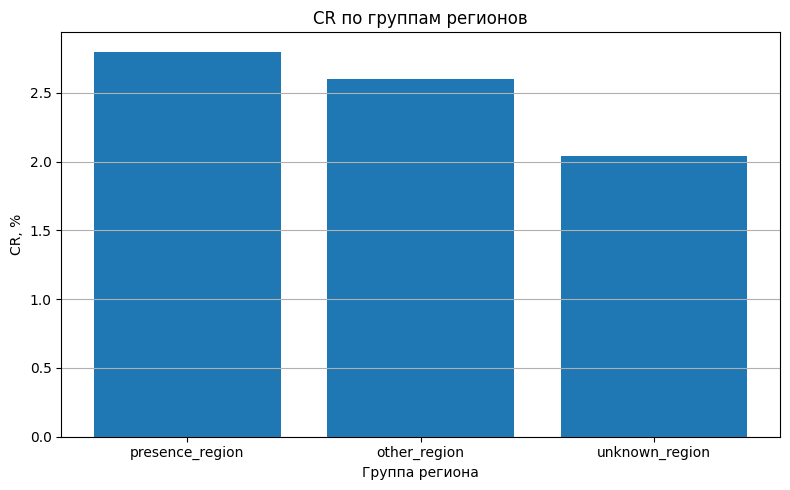

In [74]:
# Строим график CR по группам регионов
region_group_by_cr = cr_by_region_group.sort_values(
    'cr_percent', ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(region_group_by_cr['region_group'], region_group_by_cr['cr_percent'])

plt.title('CR по группам регионов')
plt.xlabel('Группа региона')
plt.ylabel('CR, %')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по CR регионов**

По городам с достаточным количеством визитов видно, что высокий CR не всегда связан с самым большим объёмом трафика. Поэтому для оценки эффективности городов важно учитывать не только показатель CR, но и количество сессий и конверсий.

Отдельно были выделены группы регионов: `presence_region`, `other_region` и `unknown_region`. К группе `presence_region` отнесены `Moscow`, `Saint Petersburg` и найденные в данных города Московской области. Эта группа имеет самый высокий CR - **2.80%**. У группы `other_region` CR немного ниже - **2.60%**, а у `unknown_region` - **2.04%**.

На этапе EDA можно предположить, что города присутствия конвертируются немного лучше остальных регионов. Однако разница между `presence_region` и `other_region` небольшая, поэтому её нужно дополнительно проверить статистически в разделе проверки гипотез.

### 8.10 Корреляционный анализ

In [75]:
# Источники, которые относятся к рекламе в социальных сетях
social_sources = [
    'QxAxdyPLuQMEcrdZWdWb',
    'MvfHsxITijuriZxsqZqt',
    'ISrKoXQCxqqYvAZICvjs',
    'IZEXUFLARCUMynmHNBGo',
    'PlbkrSYoHuZBWfYjYnfw',
    'gVRrcxiDQubJiljoTbGm',
]

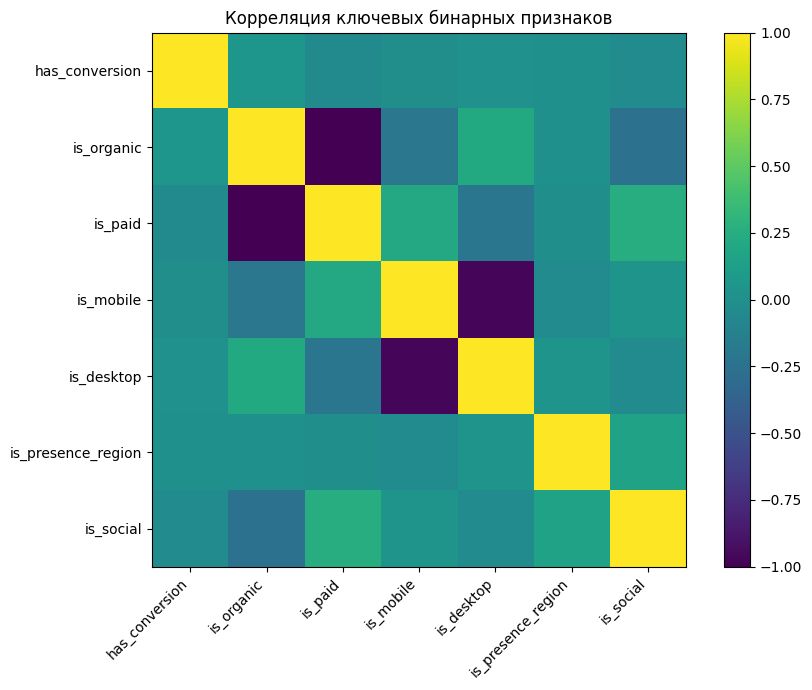

,has_conversion,is_organic,is_paid,is_mobile,is_desktop,is_presence_region,is_social
has_conversion,1.000000,0.050813,-0.050813,-0.012400,0.013237,0.007718,-0.031751
is_organic,0.050813,1.000000,-1.000000,-0.210008,0.212392,0.003341,-0.248169
is_paid,-0.050813,-1.000000,1.000000,0.210008,-0.212392,-0.003341,0.248169
is_mobile,-0.012400,-0.210008,0.210008,1.000000,-0.969943,-0.032955,0.036106
is_desktop,0.013237,0.212392,-0.212392,-0.969943,1.000000,0.034402,-0.033844
is_presence_region,0.007718,0.003341,-0.003341,-0.032955,0.034402,1.000000,0.153434
is_social,-0.031751,-0.248169,0.248169,0.036106,-0.033844,0.153434,1.000000


In [76]:
# Создаём таблицу с ключевыми бинарными признаками для корреляционного анализа
# 1 означает, что признак выполняется, 0 — не выполняется
correlation_df = pd.DataFrame(
    {
        'has_conversion': df_analysis['has_conversion'],
        'is_organic': df_analysis['utm_medium']
        .isin(['organic', 'referral', '(none)'])
        .astype(int),
        'is_paid': (
            ~df_analysis['utm_medium'].isin(['organic', 'referral', '(none)'])
        ).astype(int),
        'is_mobile': (df_analysis['device_category'] == 'mobile').astype(int),
        'is_desktop': (df_analysis['device_category'] == 'desktop').astype(
            int
        ),
        'is_presence_region': (
            df_analysis['region_group'] == 'presence_region'
        ).astype(int),
        'is_social': (df_analysis['utm_source'].isin(social_sources)).astype(
            int
        ),
    }
)

# Считаем матрицу корреляций между бинарными признаками
corr_matrix = correlation_df.corr()

# Строим heatmap корреляций
plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix)
plt.colorbar()
plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45,
    ha='right',
)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Корреляция ключевых бинарных признаков')
plt.tight_layout()
plt.show()

corr_matrix

**Вывод по корреляционному анализу**

Корреляции с фактом конверсии слабые, что ожидаемо для редкого события с общим CR около 2.7%.

При этом направление связей согласуется с дальнейшими результатами EDA и проверки гипотез: `is_organic`, `is_desktop` и `is_presence_region` имеют положительную связь с `has_conversion`, а `is_paid`, `is_mobile` и `is_social` - отрицательную.

Также видно, что некоторые признаки технически связаны между собой. Например, `is_organic` и `is_paid` имеют корреляцию -1, так как являются противоположными группами. `is_mobile` и `is_desktop` также имеют сильную отрицательную связь, потому что описывают разные категории устройств.

Таким образом, корреляционный анализ подтверждает общие направления различий между сегментами, но для бизнес-выводов важно дополнительно учитывать CR, объём трафика и количество конверсий.

### 8.11 Анализ автомобилей

In [77]:
# Смотрим примеры значений hit_page_path
display(hits['hit_page_path'].head(10))
# Смотрим примеры уникальных путей
display(hits['hit_page_path'].drop_duplicates().head(30).to_frame())

0    sberauto.com/cars?utm_source_initial=google&ut...
1    sberauto.com/cars/fiat?city=1&city=18&rental_c...
2    sberauto.com/cars/all/volkswagen/polo/e994838f...
3    sberauto.com/cars?utm_source_initial=yandex&ut...
4    sberauto.com/cars/all/mercedes-benz/cla-klasse...
5    sberauto.com/cars?utm_source_initial=youtube&u...
6    sberauto.com/cars/toyota?isnew=false&rental_ca...
7    sberauto.com/cars/all/mercedes-benz/glc/f8f330...
8    sberauto.com/cars/all/kia/sorento/c38179cb?utm...
9    sberauto.com/cars/all/nissan/x-trail/0744675f?...
Name: hit_page_path, dtype: str

,hit_page_path
0,sberauto.com/cars?utm_source_initial=google&ut...
1,sberauto.com/cars/fiat?city=1&city=18&rental_c...
2,sberauto.com/cars/all/volkswagen/polo/e994838f...
3,sberauto.com/cars?utm_source_initial=yandex&ut...
4,sberauto.com/cars/all/mercedes-benz/cla-klasse...
5,sberauto.com/cars?utm_source_initial=youtube&u...
6,sberauto.com/cars/toyota?isnew=false&rental_ca...
7,sberauto.com/cars/all/mercedes-benz/glc/f8f330...
8,sberauto.com/cars/all/kia/sorento/c38179cb?utm...
9,sberauto.com/cars/all/nissan/x-trail/0744675f?...


In [78]:
# Отбираем события, связанные со страницами конкретных автомобилей
car_page_hits = hits[
    hits['hit_page_path'].str.contains(
        r'cars/all/[^/]+/[^/]+/[^/?#]+', regex=True, na=False
    )
].copy()

display(car_page_hits['hit_page_path'].head(10).to_frame())

print('Количество событий на страницах авто:', car_page_hits.shape[0])
print('Количество уникальных сессий:', car_page_hits['session_id'].nunique())

,hit_page_path
2,sberauto.com/cars/all/volkswagen/polo/e994838f...
4,sberauto.com/cars/all/mercedes-benz/cla-klasse...
7,sberauto.com/cars/all/mercedes-benz/glc/f8f330...
8,sberauto.com/cars/all/kia/sorento/c38179cb?utm...
9,sberauto.com/cars/all/nissan/x-trail/0744675f?...
10,sberauto.com/cars/all/porsche/911/f149c91b?ren...
11,sberauto.com/cars/all/nissan/qashqai/bfc21661?...
12,sberauto.com/cars/all/renault/duster/145d53f1?...
13,sberauto.com/cars/all/porsche/911/f149c91b?ren...
14,sberauto.com/cars/all/skoda/rapid/bf24b977?ren...


Количество событий на страницах авто: 3414815
Количество уникальных сессий: 298676


In [79]:
# Извлекаем марку, модель и ID автомобиля из URL
car_page_hits[['car_brand', 'car_model', 'car_id']] = car_page_hits[
    'hit_page_path'
].str.extract(r'cars/all/([^/]+)/([^/]+)/([^/?#]+)')

display(
    car_page_hits[['hit_page_path', 'car_brand', 'car_model', 'car_id']].head(
        10
    )
)

,hit_page_path,car_brand,car_model,car_id
2,sberauto.com/cars/all/volkswagen/polo/e994838f...,volkswagen,polo,e994838f
4,sberauto.com/cars/all/mercedes-benz/cla-klasse...,mercedes-benz,cla-klasse,c917af36
7,sberauto.com/cars/all/mercedes-benz/glc/f8f330...,mercedes-benz,glc,f8f3304e
8,sberauto.com/cars/all/kia/sorento/c38179cb?utm...,kia,sorento,c38179cb
9,sberauto.com/cars/all/nissan/x-trail/0744675f?...,nissan,x-trail,0744675f
10,sberauto.com/cars/all/porsche/911/f149c91b?ren...,porsche,911,f149c91b
11,sberauto.com/cars/all/nissan/qashqai/bfc21661?...,nissan,qashqai,bfc21661
12,sberauto.com/cars/all/renault/duster/145d53f1?...,renault,duster,145d53f1
13,sberauto.com/cars/all/porsche/911/f149c91b?ren...,porsche,911,f149c91b
14,sberauto.com/cars/all/skoda/rapid/bf24b977?ren...,skoda,rapid,bf24b977


In [80]:
# Создаём общий признак автомобиля
car_page_hits['car_name'] = (
    car_page_hits['car_brand'] + ' ' + car_page_hits['car_model']
)

# Проверяем пропуски после извлечения признаков автомобиля
display(
    car_page_hits[['car_brand', 'car_model', 'car_id', 'car_name']]
    .isna()
    .sum()
    .to_frame('missing_count')
)

,missing_count
car_brand,0
car_model,0
car_id,0
car_name,0


In [81]:
# Проверяем примеры уникальных автомобилей
display(
    car_page_hits[['car_brand', 'car_model', 'car_id', 'car_name']]
    .drop_duplicates()
    .head(20)
)

,car_brand,car_model,car_id,car_name
2,volkswagen,polo,e994838f,volkswagen polo
4,mercedes-benz,cla-klasse,c917af36,mercedes-benz cla-klasse
7,mercedes-benz,glc,f8f3304e,mercedes-benz glc
8,kia,sorento,c38179cb,kia sorento
9,nissan,x-trail,0744675f,nissan x-trail
10,porsche,911,f149c91b,porsche 911
11,nissan,qashqai,bfc21661,nissan qashqai
12,renault,duster,145d53f1,renault duster
14,skoda,rapid,bf24b977,skoda rapid
17,renault,logan,8c3c73f2,renault logan


In [82]:
# Считаем количество событий и уникальных сессий по автомобилям
car_demand = (
    car_page_hits.groupby('car_name')
    .agg(
        events_count=('hit_page_path', 'count'),
        sessions_count=('session_id', 'nunique'),
    )
    .reset_index()
    .sort_values('sessions_count', ascending=False)
)

# Добавляем долю сессий автомобиля от всех сессий с просмотром авто
car_demand['sessions_share_%'] = (
    car_demand['sessions_count'] / car_page_hits['session_id'].nunique() * 100
).round(2)

display(car_demand.head(10))

,car_name,events_count,sessions_count,sessions_share_%
59,skoda rapid,442513,56865,19.04
27,lada-vaz vesta,403910,49416,16.55
68,volkswagen polo,318075,41302,13.83
56,skoda karoq,194273,25527,8.55
36,mercedes-benz e-klasse,178467,22683,7.59
46,nissan qashqai,153153,20659,6.92
47,nissan x-trail,85548,11839,3.96
22,kia rio,90249,11555,3.87
54,renault duster,76676,10956,3.67
58,skoda octavia,77005,10078,3.37


In [83]:
# Оставляем одну строку на пару сессия + автомобиль
car_sessions = car_page_hits[['session_id', 'car_name']].drop_duplicates()

display(car_sessions.head())

,session_id,car_name
2,885342191847998240.1640235807.1640235807,volkswagen polo
4,3450086108837475701.1640265078.1640265078,mercedes-benz cla-klasse
7,4024492994895054107.1640269084.1640269084,mercedes-benz glc
8,555009234841130092.1640256620.1640256620,kia sorento
9,2692901778487480807.1640206845.1640206845,nissan x-trail


In [84]:
# Добавляем информацию о конверсии только для сессий,
# которые есть в df_analysis
car_sessions = car_sessions.merge(
    df_analysis[['session_id', 'has_conversion']], on='session_id', how='inner'
)

display(car_sessions.head())

,session_id,car_name,has_conversion
0,885342191847998240.1640235807.1640235807,volkswagen polo,0
1,3450086108837475701.1640265078.1640265078,mercedes-benz cla-klasse,0
2,4024492994895054107.1640269084.1640269084,mercedes-benz glc,0
3,555009234841130092.1640256620.1640256620,kia sorento,0
4,2692901778487480807.1640206845.1640206845,nissan x-trail,0


In [85]:
# Считаем количество сессий, конверсий и CR по автомобилям
cr_by_car = (
    car_sessions.groupby('car_name')
    .agg(
        sessions_count=('session_id', 'nunique'),
        conversions_count=('has_conversion', 'sum'),
        cr_percent=('has_conversion', 'mean'),
    )
    .reset_index()
)

cr_by_car['cr_percent'] = (cr_by_car['cr_percent'] * 100).round(2)

display(cr_by_car.head())

,car_name,sessions_count,conversions_count,cr_percent
0,audi a3,2429,100,4.12
1,audi a4,1718,76,4.42
2,audi e-tron,2510,95,3.78
3,audi q5,1976,73,3.69
4,bmw 2-serii,3206,87,2.71


In [86]:
# Топ-10 автомобилей по количеству конверсий
top_cars_by_conversions = cr_by_car.sort_values(
    'conversions_count', ascending=False
).head(10)

display(top_cars_by_conversions)

,car_name,sessions_count,conversions_count,cr_percent
56,skoda rapid,56684,4043,7.13
65,volkswagen polo,41067,3423,8.34
25,lada-vaz vesta,49232,3335,6.77
53,skoda karoq,25471,1328,5.21
20,kia rio,11516,1047,9.09
33,mercedes-benz e-klasse,22633,916,4.05
43,nissan qashqai,20447,912,4.46
58,toyota camry,9720,852,8.77
55,skoda octavia,10066,713,7.08
21,kia seltos,9094,686,7.54


In [87]:
# Топ-10 автомобилей по CR среди авто с достаточным количеством сессий
min_sessions = 1000

top_cars_by_cr = (
    cr_by_car[cr_by_car['sessions_count'] >= min_sessions]
    .sort_values('cr_percent', ascending=False)
    .head(10)
)

display(top_cars_by_cr)

,car_name,sessions_count,conversions_count,cr_percent
20,kia rio,11516,1047,9.09
58,toyota camry,9720,852,8.77
16,hyundai solaris,2063,174,8.43
65,volkswagen polo,41067,3423,8.34
59,toyota corolla,3202,264,8.24
21,kia seltos,9094,686,7.54
56,skoda rapid,56684,4043,7.13
55,skoda octavia,10066,713,7.08
25,lada-vaz vesta,49232,3335,6.77
52,renault logan,9441,635,6.73


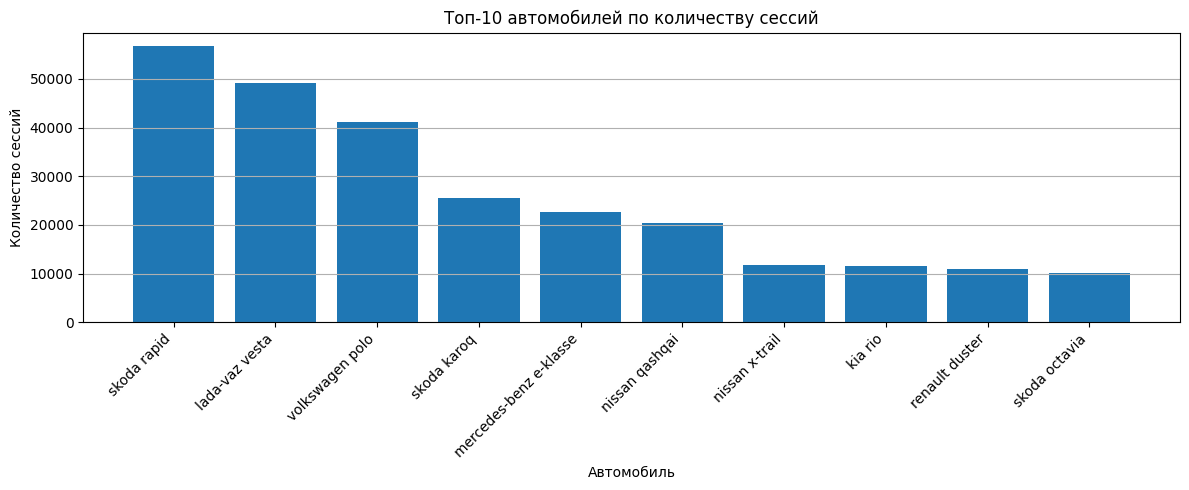

In [88]:
# Топ-10 автомобилей по количеству сессий
top_cars_by_sessions = cr_by_car.sort_values(
    'sessions_count', ascending=False
).head(10)

# Строим график топ-10 автомобилей по количеству сессий
plt.figure(figsize=(12, 5))

plt.bar(
    top_cars_by_sessions['car_name'], top_cars_by_sessions['sessions_count']
)

plt.title('Топ-10 автомобилей по количеству сессий')
plt.xlabel('Автомобиль')
plt.ylabel('Количество сессий')
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

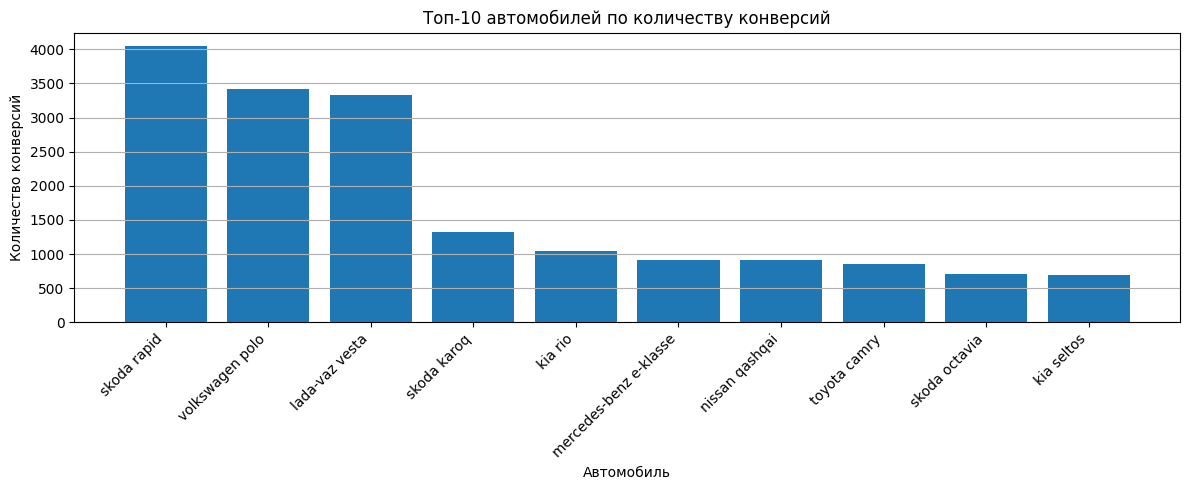

In [89]:
# Строим график топ-10 автомобилей по количеству конверсий
plt.figure(figsize=(12, 5))

plt.bar(
    top_cars_by_conversions['car_name'],
    top_cars_by_conversions['conversions_count'],
)

plt.title('Топ-10 автомобилей по количеству конверсий')
plt.xlabel('Автомобиль')
plt.ylabel('Количество конверсий')
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

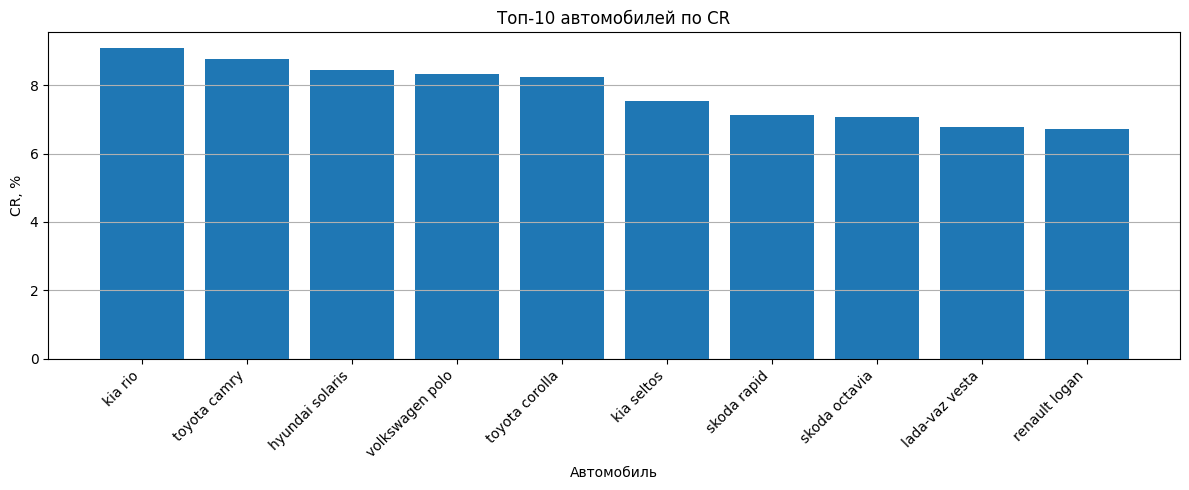

In [90]:
# Строим график топ-10 автомобилей по CR
plt.figure(figsize=(12, 5))

plt.bar(top_cars_by_cr['car_name'], top_cars_by_cr['cr_percent'])

plt.title('Топ-10 автомобилей по CR')
plt.xlabel('Автомобиль')
plt.ylabel('CR, %')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Вывод по анализу автомобилей**

Наибольший спрос по количеству сессий наблюдается у `skoda rapid`, `lada-vaz vesta` и `volkswagen polo`. Эти автомобили чаще всего просматривались пользователями и занимают крупнейшие доли среди сессий с просмотром карточек авто.

По количеству конверсий также лидируют `skoda rapid`, `volkswagen polo` и `lada-vaz vesta`, то есть самые популярные автомобили дают и основной абсолютный вклад в целевые действия.

При анализе CR видно, что самый высокий показатель конверсии среди автомобилей с достаточным количеством сессий показывают `kia rio` - **9.09%**, `toyota camry` - **8.77%**, `hyundai solaris` - **8.43%** и `volkswagen polo` - **8.34%**. Это показывает, что популярность автомобиля и эффективность по CR не всегда совпадают: часть моделей может иметь меньше просмотров, но лучше конвертироваться.

### Общий вывод по EDA

В ходе EDA была изучена структура трафика, динамика визитов, распределение по источникам, устройствам, городам, регионам и автомобилям.

Общий CR составил **2.7%**. Основной объём трафика приходит с мобильных устройств, однако `desktop` показывает более высокий CR. По географии большая часть визитов приходится на Россию, особенно на `Moscow` и `Saint Petersburg`. Группа `presence_region` имеет CR **2.80%**, что немного выше, чем у `other_region` - **2.60%**.

По источникам и типам привлечения видно, что высокий объём трафика не всегда означает высокий CR, поэтому важно учитывать одновременно количество сессий, количество конверсий и CR. Анализ автомобилей также показал, что самые популярные модели не всегда имеют самый высокий CR.

Также были рассмотрены распределения ключевых числовых признаков и построена heatmap корреляций. Корреляции с фактом конверсии оказались слабыми, поэтому для дальнейших выводов дополнительно анализируются CR, объём трафика и количество конверсий.

Полученные результаты позволяют перейти к статистической проверке гипотез и проверить, являются ли найденные различия между сегментами значимыми.

## 9. Проверка гипотез

### 9.1 Методология проверки гипотез

Для проверки гипотез используется z-критерий для двух пропорций, так как в работе сравнивается CR - доля сессий с конверсией.

Критерий Манна-Уитни больше подходит для сравнения двух независимых групп по числовому или порядковому признаку. В данном случае целевая переменная `has_conversion` является бинарной и принимает значения `0` и `1`.

Поэтому корректнее использовать тест, который напрямую проверяет различие между двумя долями. Z-критерий для двух пропорций позволяет проверить, отличается ли CR между двумя независимыми группами.

Мощность теста отдельно не рассчитывалась, так как в работе анализируются уже собранные исторические данные, а не планируется новый A/B-тест. При этом размеры сравниваемых групп достаточно большие, поэтому z-критерий для двух пропорций применим. Дополнительно результаты интерпретируются не только по p-value, но и по разнице CR в процентных пунктах, чтобы отделять статистическую значимость от бизнес-значимости.

In [91]:
alpha = 0.05

print(f'Уровень значимости: {alpha}')

Уровень значимости: 0.05


In [92]:
def calculate_conversion_table(
    df,
    group_col,
    group_1,
    group_2,
    session_col='session_id',
    conversion_col='has_conversion',
):
    """
    Считаем количество сессий, конверсий, неконверсий и CR по двум группам.
    """

    test_df = df[df[group_col].isin([group_1, group_2])].copy()

    result_table = (
        test_df.groupby(group_col)
        .agg(
            sessions_count=(session_col, 'nunique'),
            conversions_count=(conversion_col, 'sum'),
        )
        .reset_index()
    )

    result_table['non_conversions_count'] = (
        result_table['sessions_count'] - result_table['conversions_count']
    )

    result_table['cr_percent'] = (
        result_table['conversions_count']
        / result_table['sessions_count']
        * 100
    )

    result_table = (
        result_table.set_index(group_col).loc[[group_1, group_2]].reset_index()
    )

    return result_table

In [93]:
def run_proportion_ztest(result_table):
    """
    Проводим z-test для двух пропорций по таблице с результатами CR.
    """

    count = result_table['conversions_count'].tolist()
    nobs = result_table['sessions_count'].tolist()

    z_stat, p_value = proportions_ztest(
        count=count, nobs=nobs, alternative='two-sided'
    )

    return z_stat, p_value

In [94]:
def format_p_value(p_value):
    """
    Форматируем p-value для удобного вывода.
    """

    if p_value < 0.001:
        return '< 0.001'
    return f'{p_value:.3f}'

In [95]:
def run_conversion_ztest(
    df,
    group_col,
    group_1,
    group_2,
    group_1_name,
    group_2_name,
    alpha=0.05,
):
    """
    Считаем CR, проводим z-test для двух пропорций
    и выводим результат проверки гипотезы.
    """

    result_table = calculate_conversion_table(
        df=df,
        group_col=group_col,
        group_1=group_1,
        group_2=group_2,
    )

    z_stat, p_value = run_proportion_ztest(result_table)

    group_1_cr = result_table.loc[
        result_table[group_col] == group_1, 'cr_percent'
    ].iloc[0]

    group_2_cr = result_table.loc[
        result_table[group_col] == group_2, 'cr_percent'
    ].iloc[0]

    cr_difference = group_1_cr - group_2_cr

    if p_value < alpha:
        decision = 'Отвергаем H0'
        significance_result = 'получены статистические основания в пользу H1'
    else:
        decision = 'Нет оснований отвергнуть H0'
        significance_result = (
            'статистически значимое различие CR не обнаружено'
        )

    display(result_table)

    print(f'CR {group_1_name}: {group_1_cr:.2f}%')
    print(f'CR {group_2_name}: {group_2_cr:.2f}%')
    print(f'Разница CR: {cr_difference:.2f} п.п.')
    print(f'z-statistic: {z_stat:.4f}')
    print(f'p-value: {format_p_value(p_value)}')
    print(f'Решение: {decision}')
    print(f'Вывод: {significance_result}.')

    return result_table, z_stat, p_value, cr_difference

### 9.2 Organic vs Paid traffic

#### 9.2.1 Гипотеза

Проверяется, отличается ли органический трафик от платного с точки зрения CR.

* `H0`: CR органического трафика равен CR платного трафика.
* `H1`: CR органического трафика отличается от CR платного трафика.

Органический трафик определяется как сессии, у которых `utm_medium` находится в списке `('organic', 'referral', '(none)')`. Остальной трафик относится к платному.

#### 9.2.2 Подготовка групп

In [96]:
# Список значений utm_medium, которые относятся к органическому трафику
organic_mediums = ['organic', 'referral', '(none)']

hypothesis_1_df = df_analysis.copy()

# Создаём новую колонку traffic_type:
# если utm_medium входит в список organic_mediums, то трафик считается organic,
# иначе трафик считается paid
hypothesis_1_df['traffic_type'] = hypothesis_1_df['utm_medium'].apply(
    lambda medium: 'organic' if medium in organic_mediums else 'paid'
)

hypothesis_1_df['traffic_type'].value_counts()

traffic_type
paid       1344383
organic     515659
Name: count, dtype: int64

#### 9.2.3 Расчёт сессий, конверсий, CR и статистический тест

In [97]:
# Проверяем различие CR между organic и paid traffic
traffic_cr, traffic_z_stat, traffic_p_value, traffic_cr_difference = (
    run_conversion_ztest(
        df=hypothesis_1_df,
        group_col='traffic_type',
        group_1='organic',
        group_2='paid',
        group_1_name='organic traffic',
        group_2_name='paid traffic',
        alpha=alpha,
    )
)

,traffic_type,sessions_count,conversions_count,non_conversions_count,cr_percent
0,organic,515659,20812,494847,4.036001
1,paid,1344383,29502,1314881,2.194464


CR organic traffic: 4.04%
CR paid traffic: 2.19%
Разница CR: 1.84 п.п.
z-statistic: 69.3000
p-value: < 0.001
Решение: Отвергаем H0
Вывод: получены статистические основания в пользу H1.


#### 9.2.4 Интерпретация результата

CR органического трафика составил 4.04%, CR платного трафика - 2.19%. Разница между группами составила 1.84 процентных пункта в пользу органического трафика.

По результатам z-критерия для двух пропорций p-value < 0.001. При уровне значимости `alpha = 0.05` p-value меньше alpha, поэтому нулевая гипотеза отвергается.

Следовательно, получены статистические основания в пользу альтернативной гипотезы: CR органического и платного трафика различается. По фактическим значениям CR органический трафик показывает более высокий уровень конверсии, чем платный.

### 9.3 Mobile vs Desktop traffic

#### 9.3.1 Гипотеза

Проверяется, отличается ли mobile-трафик от desktop-трафика с точки зрения CR.

* `H0`: CR mobile-трафика равен CR desktop-трафика.
* `H1`: CR mobile-трафика отличается от CR desktop-трафика.

Для проверки используются только сессии, у которых `device_category` равен `mobile` или `desktop`.

#### 9.3.2 Подготовка групп

In [98]:
# Оставляем только mobile и desktop,
# так как именно эти группы сравниваются в гипотезе
hypothesis_2_df = df_analysis[
    df_analysis['device_category'].isin(['mobile', 'desktop'])
].copy()

# Проверяем количество сессий в каждой группе
hypothesis_2_df['device_category'].value_counts()

device_category
mobile     1474871
desktop     366863
Name: count, dtype: int64

#### 9.3.3 Расчёт сессий, конверсий, CR и статистический тест

In [99]:
# Проверяем различие CR между mobile и desktop traffic
device_cr, device_z_stat, device_p_value, device_cr_difference = (
    run_conversion_ztest(
        df=hypothesis_2_df,
        group_col='device_category',
        group_1='mobile',
        group_2='desktop',
        group_1_name='mobile traffic',
        group_2_name='desktop traffic',
        alpha=alpha,
    )
)

,device_category,sessions_count,conversions_count,non_conversions_count,cr_percent
0,mobile,1474871,38379,1436492,2.602194
1,desktop,366863,11513,355350,3.138229


CR mobile traffic: 2.60%
CR desktop traffic: 3.14%
Разница CR: -0.54 п.п.
z-statistic: -17.8966
p-value: < 0.001
Решение: Отвергаем H0
Вывод: получены статистические основания в пользу H1.


#### 9.3.4 Интерпретация результата

CR mobile-трафика составил 2.60%, CR desktop-трафика - 3.14%. Разница между группами составила -0.54 процентных пункта: CR desktop-трафика выше, чем CR mobile-трафика.

По результатам z-критерия для двух пропорций p-value < 0.001. При уровне значимости `alpha = 0.05` p-value меньше alpha, поэтому нулевая гипотеза отвергается.

Следовательно, получены статистические основания в пользу альтернативной гипотезы: CR mobile- и desktop-трафика различается. По фактическим значениям CR desktop-трафик показывает более высокий уровень конверсии, чем mobile-трафик.

### 9.4 Города присутствия vs другие регионы

#### 9.4.1 Гипотеза

Проверяется, отличается ли трафик из городов присутствия от трафика из других регионов с точки зрения CR.

* `H0`: CR трафика из городов присутствия равен CR трафика из других регионов.
* `H1`: CR трафика из городов присутствия отличается от CR трафика из других регионов.

К городам присутствия относятся Москва, Санкт-Петербург и найденные в данных города Московской области. Для проверки используются только группы `presence_region` и `other_region`. Группа `unknown_region` исключается из статистического теста, так как для этих сессий регион не определён.

#### 9.4.2 Подготовка групп

In [100]:
# Проверяем наличие колонки region_group
if 'region_group' not in df_analysis.columns:
    raise ValueError('Колонка region_group отсутствует в df_analysis.')

# Оставляем только города присутствия и другие регионы
# unknown_region не используем в статистическом тесте
hypothesis_3_df = df_analysis[
    df_analysis['region_group'].isin(['presence_region', 'other_region'])
].copy()

# Проверяем количество сессий в каждой группе
hypothesis_3_df['region_group'].value_counts()

region_group
presence_region    1202614
other_region        578963
Name: count, dtype: int64

#### 9.4.3 Расчёт сессий, конверсий, CR и статистический тест

In [101]:
# Проверяем различие CR между presence region и other region traffic
region_cr, region_z_stat, region_p_value, region_cr_difference = (
    run_conversion_ztest(
        df=hypothesis_3_df,
        group_col='region_group',
        group_1='presence_region',
        group_2='other_region',
        group_1_name='presence region traffic',
        group_2_name='other region traffic',
        alpha=alpha,
    )
)

,region_group,sessions_count,conversions_count,non_conversions_count,cr_percent
0,presence_region,1202614,33644,1168970,2.797573
1,other_region,578963,15073,563890,2.603448


CR presence region traffic: 2.80%
CR other region traffic: 2.60%
Разница CR: 0.19 п.п.
z-statistic: 7.4413
p-value: < 0.001
Решение: Отвергаем H0
Вывод: получены статистические основания в пользу H1.


#### 9.4.4 Интерпретация результата

CR трафика из городов присутствия составил 2.80%, CR трафика из других регионов - 2.60%. Разница между группами составила 0.19 процентных пункта в пользу городов присутствия.

По результатам z-критерия для двух пропорций p-value < 0.001. При уровне значимости `alpha = 0.05` p-value меньше alpha, поэтому нулевая гипотеза отвергается.

Следовательно, получены статистические основания в пользу альтернативной гипотезы: CR трафика из городов присутствия и CR трафика из других регионов различаются. По фактическим значениям CR трафик из городов присутствия показывает немного более высокий уровень конверсии.

При этом разница составляет только 0.19 процентных пункта, поэтому с бизнес-точки зрения эффект небольшой, несмотря на статистическую значимость.

### 9.5 Итоговая таблица результатов проверки гипотез

In [102]:
# Получаем CR нужной группы из таблицы с результатами теста
def get_cr(result_table, group_col, group_name):
    return result_table.loc[
        result_table[group_col] == group_name, 'cr_percent'
    ].iloc[0]


# Получаем CR для всех групп из результатов предыдущих гипотез
organic_cr_value = get_cr(traffic_cr, 'traffic_type', 'organic')
paid_cr_value = get_cr(traffic_cr, 'traffic_type', 'paid')

mobile_cr_value = get_cr(device_cr, 'device_category', 'mobile')
desktop_cr_value = get_cr(device_cr, 'device_category', 'desktop')

presence_cr_value = get_cr(region_cr, 'region_group', 'presence_region')
other_region_cr_value = get_cr(region_cr, 'region_group', 'other_region')


# Собираем итоговую таблицу по всем трём статистическим гипотезам
hypothesis_summary = pd.DataFrame(
    [
        {
            'Гипотеза': 'Organic vs Paid',
            'Группа 1': 'organic',
            'CR группы 1': f'{organic_cr_value:.2f}%',
            'Группа 2': 'paid',
            'CR группы 2': f'{paid_cr_value:.2f}%',
            'Разница CR': f'{traffic_cr_difference:.2f} п.п.',
            'p-value': format_p_value(traffic_p_value),
            'Решение': (
                'H0 отвергается'
                if traffic_p_value < alpha
                else 'Нет оснований отвергнуть H0'
            ),
        },
        {
            'Гипотеза': 'Mobile vs Desktop',
            'Группа 1': 'mobile',
            'CR группы 1': f'{mobile_cr_value:.2f}%',
            'Группа 2': 'desktop',
            'CR группы 2': f'{desktop_cr_value:.2f}%',
            'Разница CR': f'{device_cr_difference:.2f} п.п.',
            'p-value': format_p_value(device_p_value),
            'Решение': (
                'H0 отвергается'
                if device_p_value < alpha
                else 'Нет оснований отвергнуть H0'
            ),
        },
        {
            'Гипотеза': 'Presence region vs Other region',
            'Группа 1': 'presence_region',
            'CR группы 1': f'{presence_cr_value:.2f}%',
            'Группа 2': 'other_region',
            'CR группы 2': f'{other_region_cr_value:.2f}%',
            'Разница CR': f'{region_cr_difference:.2f} п.п.',
            'p-value': format_p_value(region_p_value),
            'Решение': (
                'H0 отвергается'
                if region_p_value < alpha
                else 'Нет оснований отвергнуть H0'
            ),
        },
    ]
)

hypothesis_summary.insert(
    1,
    'Статистический критерий и тест',
    'Z-критерий для двух пропорций, двусторонний тест, alpha = 0.05',
)

# Выводим итоговую таблицу результатов проверки гипотез
hypothesis_summary

,Гипотеза,Статистический критерий и тест,Группа 1,CR группы 1,Группа 2,CR группы 2,Разница CR,p-value,Решение
0,Organic vs Paid,"Z-критерий для двух пропорций, двусторонний те...",organic,4.04%,paid,2.19%,1.84 п.п.,< 0.001,H0 отвергается
1,Mobile vs Desktop,"Z-критерий для двух пропорций, двусторонний те...",mobile,2.60%,desktop,3.14%,-0.54 п.п.,< 0.001,H0 отвергается
2,Presence region vs Other region,"Z-критерий для двух пропорций, двусторонний те...",presence_region,2.80%,other_region,2.60%,0.19 п.п.,< 0.001,H0 отвергается


**Общий вывод по проверке гипотез**

По результатам статистической проверки все три нулевые гипотезы были отвергнуты на уровне значимости `alpha = 0.05`.

CR статистически значимо различается между organic и paid traffic, mobile- и desktop-трафиком, а также между трафиком из городов присутствия и других регионов.

Наиболее заметная разница наблюдается между organic и paid traffic: CR органического трафика выше на 1.84 процентных пункта. Desktop-трафик показывает CR выше, чем mobile-трафик, на 0.54 процентных пункта.

Для городов присутствия различие тоже статистически значимо, но размер эффекта небольшой: CR выше только на 0.19 процентных пункта. Поэтому этот результат нужно интерпретировать осторожно с точки зрения бизнес-значимости.

## 10. Ответы на вопросы продуктовой команды

### 10.1 Самый целевой трафик по источникам, кампаниям, устройствам и локациям

#### 10.1.1 Методика оценки целевого трафика

В этом разделе анализируется, из каких источников, кампаний, устройств и локаций приходит самый целевой трафик.

Целевой трафик оценивается не только по CR, но и по объёму: количеству сессий и количеству конверсий. Это важно, потому что высокий CR при маленьком количестве сессий может быть нестабильным и не всегда подходит для бизнес-выводов.

Поэтому в анализе будут учитываться несколько показателей:

* количество сессий;
* количество конверсий;
* CR;
* доля сегмента в общем трафике;
* доля сегмента во всех конверсиях.

Наиболее целевыми будем считать сегменты, которые одновременно дают заметный объём трафика, достаточное количество конверсий и CR выше среднего.

В этом разделе используются результаты EDA, однако для удобства бизнес-интерпретации ключевые метрики будут дополнительно собраны в итоговые сводные таблицы.

#### 10.1.2 Общий CR и функция для сегментного анализа

In [103]:
# Считаем общий CR по всем сессиям
overall_cr = df_analysis['has_conversion'].mean() * 100

# Минимальный порог сессий для анализа CR по сегментам
min_sessions = 1000

print(f'Общий CR: {overall_cr:.2f}%')
print(f'Минимальный порог сессий для анализа сегментов: {min_sessions}')

Общий CR: 2.70%
Минимальный порог сессий для анализа сегментов: 1000


In [104]:
def calculate_segment_metrics(
    df,
    group_col,
    min_sessions=1000,
    session_col='session_id',
    conversion_col='has_conversion',
):
    """
    Считаем ключевые метрики по сегментам:
    количество сессий, количество конверсий, CR,
    долю сегмента в общем трафике, долю сегмента в конверсиях
    и отличие CR от среднего CR.
    """

    # Считаем количество сессий и конверсий по сегментам
    segment_metrics = (
        df.groupby(group_col)
        .agg(
            sessions_count=(session_col, 'nunique'),
            conversions_count=(conversion_col, 'sum'),
        )
        .reset_index()
    )

    # Считаем CR по сегментам
    segment_metrics['cr_percent'] = (
        segment_metrics['conversions_count']
        / segment_metrics['sessions_count']
        * 100
    )

    # Считаем долю сегмента в общем трафике
    segment_metrics['traffic_share_percent'] = (
        segment_metrics['sessions_count']
        / segment_metrics['sessions_count'].sum()
        * 100
    )

    # Считаем долю сегмента во всех конверсиях
    segment_metrics['conversion_share_percent'] = (
        segment_metrics['conversions_count']
        / segment_metrics['conversions_count'].sum()
        * 100
    )

    # Считаем отличие CR сегмента от общего CR
    segment_metrics['cr_diff_from_avg_pp'] = (
        segment_metrics['cr_percent'] - overall_cr
    )

    # Оставляем только сегменты с достаточным количеством сессий
    segment_metrics = segment_metrics[
        segment_metrics['sessions_count'] >= min_sessions
    ].copy()

    return segment_metrics

#### 10.1.3 Источники трафика

На этом этапе анализируются источники трафика (`utm_source`). Для оценки используются количество сессий, количество конверсий и CR. Отдельно рассматриваются источники с наибольшим объёмом трафика, с наибольшим количеством конверсий и с самым высоким CR.

In [105]:
# Рассчитываем метрики по источникам трафика
source_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='utm_source',
    min_sessions=min_sessions,
)

source_metrics.head()

,utm_source,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345,6.253622,7.715546,0.632353
6,BKeImrJuRDZcHiSSTdzm,1464,98,6.693989,0.078708,0.194777,3.988996
23,DnEUulZAecfGPvdtZBYS,1420,76,5.352113,0.076342,0.151051,2.647120
40,GpAkIXsclxDGyILfNlrR,2116,14,0.661626,0.113761,0.027825,-2.043367
41,HFaOtpcChAlcMuxEAlpu,1136,29,2.552817,0.061074,0.057638,-0.152176


In [106]:
# Источники с самым большим количеством сессий
top_sources_by_sessions = source_metrics.sort_values(
    'sessions_count', ascending=False
).head(10)

top_sources_by_sessions

,utm_source,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.766432,31.090158,31.796319,0.061439
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.503618,16.159581,20.930556,0.798625
217,kjsLglQLzykiRbcDiGcD,266354,6293,2.362645,14.319784,12.507453,-0.342347
79,MvfHsxITijuriZxsqZqt,186199,2249,1.207848,10.010473,4.469929,-1.497145
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345,6.253622,7.715546,0.632353
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.432753,5.499177,11.044640,2.727760
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721,2.764185,2.790476,0.025728
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792,1.674801,3.631196,3.159799
212,jaSOmLICuBzCFqHfBdRg,29241,401,1.371362,1.572061,0.796995,-1.333631
107,RmEBuqrriAfAVsLQQmhk,28055,139,0.495455,1.508299,0.276265,-2.209537


In [107]:
# Источники с самым большим количеством конверсий
top_sources_by_conversions = source_metrics.sort_values(
    'conversions_count', ascending=False
).head(10)

top_sources_by_conversions

,utm_source,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.766432,31.090158,31.796319,0.061439
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.503618,16.159581,20.930556,0.798625
217,kjsLglQLzykiRbcDiGcD,266354,6293,2.362645,14.319784,12.507453,-0.342347
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.432753,5.499177,11.044640,2.727760
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345,6.253622,7.715546,0.632353
79,MvfHsxITijuriZxsqZqt,186199,2249,1.207848,10.010473,4.469929,-1.497145
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792,1.674801,3.631196,3.159799
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721,2.764185,2.790476,0.025728
212,jaSOmLICuBzCFqHfBdRg,29241,401,1.371362,1.572061,0.796995,-1.333631
241,oZCzWSykfixnjMPDNjSU,3143,260,8.272351,0.168975,0.516755,5.567359


In [108]:
# Источники с самым высоким CR при достаточном количестве сессий
top_sources_by_cr = source_metrics.sort_values(
    'cr_percent', ascending=False
).head(10)

top_sources_by_cr

,utm_source,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
241,oZCzWSykfixnjMPDNjSU,3143,260,8.272351,0.168975,0.516755,5.567359
6,BKeImrJuRDZcHiSSTdzm,1464,98,6.693989,0.078708,0.194777,3.988996
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792,1.674801,3.631196,3.159799
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.432753,5.499177,11.044640,2.727760
23,DnEUulZAecfGPvdtZBYS,1420,76,5.352113,0.076342,0.151051,2.647120
218,klTrhUaShgnjIbaPmqjc,1197,42,3.508772,0.064353,0.083476,0.803779
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.503618,16.159581,20.930556,0.798625
128,WEXkMlsnJodrzBgKJBpG,1003,35,3.489531,0.053924,0.069563,0.784539
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345,6.253622,7.715546,0.632353
60,KgicpPxiEQfzPlPwQZJq,1761,55,3.123225,0.094675,0.109314,0.418233


**Вывод по источникам**

По источникам трафика видно, что основной объём сессий дают `ZpYIoDJMcFzVoPFsHGJL`, `fDLlAcSmythWSCVMvqvL` и `kjsLglQLzykiRbcDiGcD`. На них приходится значительная часть всего трафика.

По количеству конверсий также лидируют `ZpYIoDJMcFzVoPFsHGJL` и `fDLlAcSmythWSCVMvqvL`. Источник `ZpYIoDJMcFzVoPFsHGJL` даёт 31.09% всех сессий и 31.80% всех конверсий, поэтому его можно считать ключевым источником по объёму.

По CR лучшие значения показывают `oZCzWSykfixnjMPDNjSU`, `BKeImrJuRDZcHiSSTdzm`, `aXQzDWsJuGXeBXexNHjc` и `bByPQxmDaMXgpHeypKSM`. Однако первые два источника имеют небольшой объём трафика, поэтому их высокий CR нужно интерпретировать осторожно.

Наиболее ценными с точки зрения сочетания объёма и качества выглядят `fDLlAcSmythWSCVMvqvL` и `bByPQxmDaMXgpHeypKSM`: они дают заметное количество сессий и конверсий, а их CR выше среднего. Источник `ZpYIoDJMcFzVoPFsHGJL` остаётся главным по объёму и числу конверсий, но его CR почти на уровне среднего.

#### 10.1.4 Анализ типов привлечения

На этом этапе анализируются типы привлечения (`utm_medium`). Для оценки используются количество сессий, количество конверсий и CR.

In [109]:
medium_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='utm_medium',
    min_sessions=min_sessions,
)

medium_metrics.head()

,utm_medium,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
0,(none),300575,10531,3.503618,16.159581,20.930556,0.798625
2,app,2836,11,0.387870,0.152470,0.021863,-2.317122
4,banner,552272,15107,2.735427,29.691373,30.025440,0.030435
5,blogger_channel,8015,162,2.021210,0.430904,0.321978,-0.683782
7,blogger_stories,4312,35,0.811688,0.231823,0.069563,-1.893304


In [110]:
# Типы привлечения с самым большим количеством сессий
top_mediums_by_sessions = medium_metrics.sort_values(
    'sessions_count', ascending=False
).head(10)

top_mediums_by_sessions

,utm_medium,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
4,banner,552272,15107,2.735427,29.691373,30.025440,0.030435
12,cpc,434794,9529,2.191613,23.375494,18.939063,-0.513380
0,(none),300575,10531,3.503618,16.159581,20.930556,0.798625
13,cpm,242123,2522,1.041619,13.017072,5.012521,-1.663373
40,referral,152050,8181,5.380467,8.174547,16.259888,2.675474
30,organic,63034,2100,3.331535,3.388848,4.173789,0.626543
17,email,29240,401,1.371409,1.572008,0.796995,-1.333584
36,push,28035,840,2.996255,1.507224,1.669515,0.291262
48,stories,10582,126,1.190701,0.568912,0.250427,-1.514291
14,cpv,8022,115,1.433558,0.431281,0.228565,-1.271435


In [111]:
# Типы привлечения с самым большим количеством конверсий
top_mediums_by_conversions = medium_metrics.sort_values(
    'conversions_count', ascending=False
).head(10)

top_mediums_by_conversions

,utm_medium,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
4,banner,552272,15107,2.735427,29.691373,30.025440,0.030435
0,(none),300575,10531,3.503618,16.159581,20.930556,0.798625
12,cpc,434794,9529,2.191613,23.375494,18.939063,-0.513380
40,referral,152050,8181,5.380467,8.174547,16.259888,2.675474
13,cpm,242123,2522,1.041619,13.017072,5.012521,-1.663373
30,organic,63034,2100,3.331535,3.388848,4.173789,0.626543
36,push,28035,840,2.996255,1.507224,1.669515,0.291262
17,email,29240,401,1.371409,1.572008,0.796995,-1.333584
43,smartbanner,6794,179,2.634678,0.365261,0.355766,-0.070315
5,blogger_channel,8015,162,2.021210,0.430904,0.321978,-0.683782


In [112]:
# Типы привлечения с самым высоким CR при достаточном количестве сессий
top_mediums_by_cr = medium_metrics.sort_values(
    'cr_percent', ascending=False
).head(10)

top_mediums_by_cr

,utm_medium,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
40,referral,152050,8181,5.380467,8.174547,16.259888,2.675474
44,smm,1985,87,4.382872,0.106718,0.172914,1.677879
0,(none),300575,10531,3.503618,16.159581,20.930556,0.798625
30,organic,63034,2100,3.331535,3.388848,4.173789,0.626543
11,cpa,4279,131,3.061463,0.230049,0.260365,0.356470
36,push,28035,840,2.996255,1.507224,1.669515,0.291262
4,banner,552272,15107,2.735427,29.691373,30.025440,0.030435
43,smartbanner,6794,179,2.634678,0.365261,0.355766,-0.070315
33,post,2326,54,2.321582,0.125051,0.107326,-0.383411
12,cpc,434794,9529,2.191613,23.375494,18.939063,-0.513380


**Вывод по типам привлечения**

По объёму трафика лидируют `banner`, `cpc`, `(none)` и `cpm`. Наибольшую долю сессий даёт `banner`, при этом его CR почти соответствует среднему уровню.

По количеству конверсий также сильными выглядят `banner`, `(none)`, `cpc` и `referral`. При этом `referral` особенно выделяется: он даёт меньшую долю трафика, чем `banner` и `cpc`, но показывает высокий CR и заметную долю конверсий.

По CR лучшие результаты показывают `referral`, `(none)`, `organic` и `smm`. Однако `smm` имеет небольшой объём трафика, поэтому его высокий CR нужно интерпретировать осторожно.

Таким образом, по CR сильными выглядят `referral`, `(none)` и `organic`. При этом `(none)` нужно интерпретировать осторожно, так как это не конкретный рекламный канал, а трафик без явно определённого `utm_medium`. С точки зрения управляемых каналов наиболее качественными выглядят `referral` и `organic`. `banner` остаётся важным каналом по объёму, а `cpc` и `cpm` требуют дополнительного анализа из-за большого объёма трафика при CR ниже среднего.

#### 10.1.5 Анализ рекламных кампаний

На этом этапе анализируются рекламные кампании (`utm_campaign`). Для оценки используются количество сессий, количество конверсий и CR. Отдельно рассматриваются кампании с наибольшим объёмом трафика, с наибольшим количеством конверсий и с самым высоким CR.

In [113]:
# Рассчитываем метрики по рекламным кампаниям
campaign_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='utm_campaign',
    min_sessions=min_sessions,
)

campaign_metrics.head()

,utm_campaign,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
1,AqudXfUnmXWSDWVGYaXr,2583,10,0.387147,0.138868,0.019875,-2.317846
7,BVKxkCOHKUOvkpbrLMgZ,2539,52,2.048050,0.136502,0.103351,-0.656942
16,CdkIkBrvEVomSgvHzYvj,1390,4,0.287770,0.074729,0.007950,-2.417223
25,DXVdsSTQphSYVmRchYKt,1181,5,0.423370,0.063493,0.009938,-2.281623
27,DZlFqIVHUBIDaQoarvIZ,1558,30,1.925546,0.083762,0.059626,-0.779447


In [114]:
# Кампании с самым большим количеством сессий
top_campaigns_by_sessions = campaign_metrics.sort_values(
    'sessions_count', ascending=False
).head(10)

top_campaigns_by_sessions

,utm_campaign,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
88,LTuZkdKfxRGVceoWkVyg,463481,19006,4.100707,24.917771,37.774774,1.395715
85,LEoPHuyFvzoNfnzGgfcd,324044,9348,2.884793,17.421327,18.579322,0.179801
40,FTjNLDyTrXaWYgZymFkV,247360,2447,0.989246,13.298624,4.863457,-1.715746
363,unknown,219603,7174,3.266804,11.806346,14.258457,0.561812
258,gecBYcKZCPMcVYdSSzKP,134042,4545,3.390728,7.206396,9.033271,0.685736
156,TmThBvoCcwkCZZUWACYq,26597,123,0.462458,1.429914,0.244465,-2.242535
193,XHNUiSKKGTEpSAlaVMFQ,24524,401,1.635133,1.318465,0.796995,-1.069860
320,okTXSMadDkjvntEHzIjp,24511,77,0.314145,1.317766,0.153039,-2.390848
147,SgIUDYUKnyWHVowUOqid,22841,373,1.633028,1.227983,0.741344,-1.071964
352,sbJRYgVfvcnqKJNDDYIr,20188,575,2.848227,1.085352,1.142823,0.143234


In [115]:
# Кампании с самым большим количеством конверсий
top_campaigns_by_conversions = campaign_metrics.sort_values(
    'conversions_count', ascending=False
).head(10)

top_campaigns_by_conversions

,utm_campaign,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
88,LTuZkdKfxRGVceoWkVyg,463481,19006,4.100707,24.917771,37.774774,1.395715
85,LEoPHuyFvzoNfnzGgfcd,324044,9348,2.884793,17.421327,18.579322,0.179801
363,unknown,219603,7174,3.266804,11.806346,14.258457,0.561812
258,gecBYcKZCPMcVYdSSzKP,134042,4545,3.390728,7.206396,9.033271,0.685736
40,FTjNLDyTrXaWYgZymFkV,247360,2447,0.989246,13.298624,4.863457,-1.715746
352,sbJRYgVfvcnqKJNDDYIr,20188,575,2.848227,1.085352,1.142823,0.143234
193,XHNUiSKKGTEpSAlaVMFQ,24524,401,1.635133,1.318465,0.796995,-1.069860
147,SgIUDYUKnyWHVowUOqid,22841,373,1.633028,1.227983,0.741344,-1.071964
93,LwJZxKuWmvOhPsaCeRjG,17615,285,1.617939,0.947022,0.566443,-1.087053
411,zxoiLxhuSIFrCeTLQVWZ,12370,270,2.182700,0.665039,0.536630,-0.522293


In [116]:
# Кампании с самым высоким CR при достаточном количестве сессий
top_campaigns_by_cr = campaign_metrics.sort_values(
    'cr_percent', ascending=False
).head(10)

top_campaigns_by_cr

,utm_campaign,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
34,EiQppLFrUZrUsjXVulLg,1252,110,8.785942,0.067310,0.218627,6.080950
181,WJUKqfeOrjXIOHjgcgdR,1146,76,6.631763,0.061612,0.151051,3.926770
31,DsqwamlMwRgMTyspCjFR,2829,172,6.079887,0.152093,0.341853,3.374894
201,YDIkQmcjRkpdxGbLLtNN,2651,161,6.073180,0.142524,0.319990,3.368187
131,QejVLgNgzFMqjZPsnfxa,1724,89,5.162413,0.092686,0.176889,2.457420
312,ngkgBNjlzLYBofkljaBo,1615,73,4.520124,0.086826,0.145089,1.815131
266,hkvDVxqLOzGjGaoNiNzN,4445,184,4.139483,0.238973,0.365703,1.434490
88,LTuZkdKfxRGVceoWkVyg,463481,19006,4.100707,24.917771,37.774774,1.395715
292,kwdmElMUPDZaLQdgjcsI,1107,45,4.065041,0.059515,0.089438,1.360048
50,HEimDfYZIzuQXDZAAcEW,3987,139,3.486331,0.214350,0.276265,0.781338


In [117]:
# Проверяем показатели кампании unknown, если она есть в данных
campaign_metrics[campaign_metrics['utm_campaign'] == 'unknown']

,utm_campaign,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
363,unknown,219603,7174,3.266804,11.806346,14.258457,0.561812


**Вывод по рекламным кампаниям**

По объёму трафика лидируют кампании `LTuZkdKfxRGVceoWkVyg`, `LEoPHuyFvzoNfnzGgfcd` и `FTjNLDyTrXaWYgZymFkV`. Самый большой объём даёт кампания `LTuZkdKfxRGVceoWkVyg`: 24.92% всех сессий.

По количеству конверсий также лидирует `LTuZkdKfxRGVceoWkVyg`: на неё приходится 37.77% всех конверсий при CR 4.10%, что заметно выше среднего. Поэтому эту кампанию можно считать наиболее ценной с точки зрения сочетания объёма и качества трафика.

По CR лучшие значения показывают кампании `EiQppLFrUZrUsjXVulLg`, `WJUKqfeOrjXIOHjgcgdR`, `DsqwamlMwRgMTyspCjFR` и `YDIkQmcjRkpdxGbLLtNN`. Однако у них небольшой объём трафика, поэтому высокий CR нужно интерпретировать осторожно.

Кампания `FTjNLDyTrXaWYgZymFkV` даёт большой объём сессий, но показывает низкий CR - 0.99%. Это может быть зоной для дополнительного анализа и оптимизации.

Также заметную долю занимает группа `unknown`: 11.81% всех сессий и 14.26% всех конверсий при CR 3.27%. Так как кампания не определена, этот сегмент нельзя полноценно интерпретировать как конкретную рекламную кампанию.

#### 10.1.6 Анализ устройств

На этом этапе анализируется трафик по типам устройств (`device_category`). Для оценки используются количество сессий, количество конверсий и CR. Также результат сопоставляется с проверкой гипотезы о различии CR между mobile- и desktop-трафиком.

In [118]:
# Рассчитываем метрики по типам устройств
device_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='device_category',
    min_sessions=min_sessions,
)

# Сортируем устройства по количеству сессий
device_metrics = device_metrics.sort_values('sessions_count', ascending=False)

device_metrics

,device_category,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
1,mobile,1474871,38379,2.602194,79.292349,76.278968,-0.102799
0,desktop,366863,11513,3.138229,19.723372,22.882299,0.433236
2,tablet,18308,422,2.305003,0.984279,0.838733,-0.399989


**Вывод по устройствам**

Основной объём трафика приходит с мобильных устройств: `mobile` даёт 79.29% всех сессий и 76.28% всех конверсий. При этом CR mobile-трафика составляет 2.60%, что немного ниже среднего уровня.

Desktop-трафик даёт меньший объём сессий - 19.72%, но показывает более высокий CR - 3.14%. Также на desktop приходится 22.88% всех конверсий, что выше его доли в общем трафике.

Этот результат согласуется с проверкой гипотезы в разделе 9.3: CR mobile- и desktop-трафика статистически значимо различается, а desktop показывает более высокий уровень конверсии.

Таким образом, desktop-трафик выглядит более качественным с точки зрения CR, но mobile остаётся ключевым по объёму. Поэтому мобильный трафик нельзя игнорировать: улучшение мобильного пользовательского пути может дать заметный эффект из-за большого количества сессий.

#### 10.1.7 Анализ локаций

На этом этапе анализируется трафик по локациям. Сначала рассматриваются укрупнённые региональные группы (`region_group`), затем - отдельные города (`geo_city_clean`). Для оценки используются количество сессий, количество конверсий и CR.

In [119]:
# Рассчитываем метрики по региональным группам
region_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='region_group',
    min_sessions=min_sessions,
)

# Сортируем региональные группы по количеству сессий
region_metrics = region_metrics.sort_values('sessions_count', ascending=False)

region_metrics

,region_group,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
1,presence_region,1202614,33644,2.797573,64.655207,66.868069,0.092580
0,other_region,578963,15073,2.603448,31.126340,29.957865,-0.101545
2,unknown_region,78465,1597,2.035302,4.218453,3.174067,-0.669690


In [120]:
# Рассчитываем метрики по городам
city_metrics = calculate_segment_metrics(
    df=df_analysis,
    group_col='geo_city_clean',
    min_sessions=min_sessions,
)

city_metrics.head()

,geo_city_clean,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
59,Altoona,1235,0,0.000000,0.066396,0.000000,-2.704993
74,Anapa,1182,33,2.791878,0.063547,0.065588,0.086885
108,Arkhangelsk,1547,33,2.133161,0.083170,0.065588,-0.571832
124,Ashburn,2022,0,0.000000,0.108707,0.000000,-2.704993
129,Astrakhan,1820,35,1.923077,0.097847,0.069563,-0.781916


In [121]:
# Отдельно смотрим сегмент unknown, если он есть в данных
unknown_city_metrics = city_metrics[
    city_metrics['geo_city_clean'] == 'unknown'
]

display(unknown_city_metrics)

# Исключаем unknown из анализа городов
city_metrics_known = city_metrics[
    city_metrics['geo_city_clean'] != 'unknown'
].copy()

,geo_city_clean,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
2517,unknown,78465,1597,2.035302,4.218453,3.174067,-0.66969


In [122]:
# Города с самым большим количеством сессий
top_cities_by_sessions = city_metrics_known.sort_values(
    'sessions_count', ascending=False
).head(10)

top_cities_by_sessions

,geo_city_clean,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
1406,Moscow,805329,23629,2.934080,43.296280,46.963072,0.229088
1902,Saint Petersburg,296788,7113,2.396660,15.955984,14.137218,-0.308332
2455,Yekaterinburg,35788,887,2.478484,1.924043,1.762929,-0.226508
1082,Krasnodar,32243,1081,3.352666,1.733455,2.148507,0.647673
975,Kazan,29531,1139,3.856964,1.587652,2.263783,1.151971
1921,Samara,24992,727,2.908931,1.343626,1.444926,0.203938
1518,Nizhny Novgorod,22227,559,2.514959,1.194973,1.111023,-0.190033
2271,Ufa,21679,639,2.947553,1.165511,1.270024,0.242560
1557,Novosibirsk,21568,509,2.359978,1.159544,1.011647,-0.345015
1089,Krasnoyarsk,16346,376,2.300257,0.878797,0.747307,-0.404736


In [123]:
# Города с самым большим количеством конверсий
top_cities_by_conversions = city_metrics_known.sort_values(
    'conversions_count', ascending=False
).head(10)

top_cities_by_conversions

,geo_city_clean,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
1406,Moscow,805329,23629,2.934080,43.296280,46.963072,0.229088
1902,Saint Petersburg,296788,7113,2.396660,15.955984,14.137218,-0.308332
975,Kazan,29531,1139,3.856964,1.587652,2.263783,1.151971
1082,Krasnodar,32243,1081,3.352666,1.733455,2.148507,0.647673
2455,Yekaterinburg,35788,887,2.478484,1.924043,1.762929,-0.226508
1921,Samara,24992,727,2.908931,1.343626,1.444926,0.203938
2271,Ufa,21679,639,2.947553,1.165511,1.270024,0.242560
1518,Nizhny Novgorod,22227,559,2.514959,1.194973,1.111023,-0.190033
1557,Novosibirsk,21568,509,2.359978,1.159544,1.011647,-0.345015
2252,Tula,15814,438,2.769698,0.850196,0.870533,0.064705


In [124]:
# Города с самым высоким CR при достаточном количестве сессий
top_cities_by_cr = city_metrics_known.sort_values(
    'cr_percent', ascending=False
).head(10)

top_cities_by_cr

,geo_city_clean,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
550,Domodedovo,4038,263,6.513125,0.217092,0.522717,3.808133
1280,Makhachkala,2607,139,5.331799,0.140158,0.276265,2.626806
1450,Nalchik,1099,52,4.731574,0.059085,0.103351,2.026581
2354,Vladikavkaz,1149,54,4.699739,0.061773,0.107326,1.994746
2110,Stavropol,4377,180,4.112406,0.235317,0.357753,1.407413
975,Kazan,29531,1139,3.856964,1.587652,2.263783,1.151971
1055,Korolyov,4047,145,3.582901,0.217576,0.288190,0.877908
422,Cheboksary,2320,83,3.577586,0.124728,0.164964,0.872594
2055,Sochi,8972,316,3.522069,0.482355,0.628056,0.817076
1213,Lobnya,1984,68,3.427419,0.106664,0.135151,0.722427


**Вывод по локациям**

Основной объём трафика приходит из городов присутствия: `presence_region` даёт 64.66% всех сессий и 66.87% всех конверсий. CR этой группы составляет 2.80%, что немного выше среднего.

Среди конкретных городов по объёму сессий и конверсий лидируют Moscow и Saint Petersburg. Moscow является ключевой локацией: на неё приходится 43.30% всех сессий и 46.96% всех конверсий.

По CR среди известных городов выделяются Domodedovo, Makhachkala, Nalchik, Vladikavkaz и Stavropol, но их объём трафика меньше, поэтому высокий CR нужно интерпретировать осторожно.

Сегменты `unknown_region` и `unknown` не используются для географических бизнес-выводов, так как регион или город не определён.

#### 10.1.8 Общий вывод по целевому трафику

Самый целевой трафик нужно оценивать не только по CR, но и по объёму сессий и конверсий.

По источникам наиболее сильными выглядят `fDLlAcSmythWSCVMvqvL` и `bByPQxmDaMXgpHeypKSM`, так как они сочетают заметный объём трафика, количество конверсий и CR выше среднего. Источник `ZpYIoDJMcFzVoPFsHGJL` является ключевым по объёму и количеству конверсий, но его CR близок к среднему.

По типам привлечения высокий CR показывают `referral`, `(none)` и `organic`. При этом `(none)` нужно интерпретировать осторожно, так как это не конкретный рекламный канал, а трафик без явно определённого `utm_medium`. Поэтому с точки зрения управляемых каналов наиболее качественными выглядят `referral` и `organic`.

`banner` остаётся важным каналом по объёму, а `cpc` и `cpm` требуют дополнительного анализа из-за большого объёма трафика при CR ниже среднего.

По рекламным кампаниям наиболее ценной выглядит кампания `LTuZkdKfxRGVceoWkVyg`: она даёт большой объём сессий, больше всего конверсий и CR выше среднего.

По устройствам desktop-трафик показывает более высокий CR, чем mobile-трафик. Однако mobile даёт основную часть сессий и конверсий, поэтому его нельзя игнорировать.

По локациям основной вклад дают города присутствия, особенно Moscow и Saint Petersburg. При этом сегменты `unknown_region` и `unknown` не используются для географических бизнес-выводов, так как регион или город не определён.

### 10.2 Автомобили с наибольшим спросом и лучшим CR

#### 10.2.1 Методика анализа автомобилей

В этом разделе анализируется интерес пользователей к автомобилям на сайте.

Спрос на автомобиль оценивается по количеству уникальных сессий, в которых пользователь просматривал страницу конкретного автомобиля. Для оценки качества спроса дополнительно рассчитывается CR - доля таких сессий, в которых было совершено целевое действие.

Важно учитывать не только CR, но и объём сессий. Автомобиль с небольшим количеством просмотров может показать высокий CR случайно, поэтому для анализа CR используется минимальный порог по количеству сессий.

Если в одной сессии пользователь просматривал несколько автомобилей, такая сессия может учитываться в статистике по нескольким моделям. Это допустимо, так как в этом разделе анализируется интерес к конкретным автомобилям, а не общее количество уникальных сессий сайта.

In [125]:
cr_by_car.head()

,car_name,sessions_count,conversions_count,cr_percent
0,audi a3,2429,100,4.12
1,audi a4,1718,76,4.42
2,audi e-tron,2510,95,3.78
3,audi q5,1976,73,3.69
4,bmw 2-serii,3206,87,2.71


#### 10.2.2 Спрос и CR по автомобилям

In [126]:
top_cars_by_sessions

,car_name,sessions_count,conversions_count,cr_percent
56,skoda rapid,56684,4043,7.13
25,lada-vaz vesta,49232,3335,6.77
65,volkswagen polo,41067,3423,8.34
53,skoda karoq,25471,1328,5.21
33,mercedes-benz e-klasse,22633,916,4.05
43,nissan qashqai,20447,912,4.46
44,nissan x-trail,11686,497,4.25
20,kia rio,11516,1047,9.09
51,renault duster,10866,402,3.70
55,skoda octavia,10066,713,7.08


In [127]:
top_cars_by_conversions

,car_name,sessions_count,conversions_count,cr_percent
56,skoda rapid,56684,4043,7.13
65,volkswagen polo,41067,3423,8.34
25,lada-vaz vesta,49232,3335,6.77
53,skoda karoq,25471,1328,5.21
20,kia rio,11516,1047,9.09
33,mercedes-benz e-klasse,22633,916,4.05
43,nissan qashqai,20447,912,4.46
58,toyota camry,9720,852,8.77
55,skoda octavia,10066,713,7.08
21,kia seltos,9094,686,7.54


In [128]:
top_cars_by_cr

,car_name,sessions_count,conversions_count,cr_percent
20,kia rio,11516,1047,9.09
58,toyota camry,9720,852,8.77
16,hyundai solaris,2063,174,8.43
65,volkswagen polo,41067,3423,8.34
59,toyota corolla,3202,264,8.24
21,kia seltos,9094,686,7.54
56,skoda rapid,56684,4043,7.13
55,skoda octavia,10066,713,7.08
25,lada-vaz vesta,49232,3335,6.77
52,renault logan,9441,635,6.73


#### 10.2.3 Вывод по автомобилям

Наибольший спрос по количеству сессий показывают `skoda rapid`, `lada-vaz vesta` и `volkswagen polo`. Эти модели чаще всего просматривались пользователями, поэтому их можно считать наиболее востребованными с точки зрения интереса на сайте.

По количеству конверсий также лидируют `skoda rapid`, `volkswagen polo` и `lada-vaz vesta`. Это значит, что высокий интерес к этим автомобилям сопровождается большим количеством целевых действий.

Лучший CR среди автомобилей с достаточным количеством сессий показывают `kia rio`, `toyota camry`, `hyundai solaris` и `volkswagen polo`. Однако при интерпретации CR важно учитывать объём: например, `volkswagen polo` сочетает высокий CR с большим количеством сессий и конверсий.

Таким образом, наиболее сильными моделями с точки зрения сочетания спроса и качества трафика выглядят `skoda rapid`, `volkswagen polo` и `lada-vaz vesta`. Отдельно стоит отметить `kia rio` и `toyota camry`: они показывают высокий CR и заметное количество конверсий.

### 10.3 Оценка эффективности рекламы в социальных сетях

#### 10.3.1 Методика анализа соцсетей

В этом разделе оценивается эффективность трафика из социальных сетей.

Для анализа используются источники `utm_source`, которые в методичке отнесены к рекламе в социальных сетях. Эффективность оценивается по нескольким метрикам:

- количество сессий;
- количество конверсий;
- CR;
- доля social traffic в общем трафике;
- доля social traffic во всех конверсиях.

Решение о том, стоит ли увеличивать присутствие в социальных сетях, должно учитывать не только CR, но и объём трафика. Если social traffic показывает низкий CR или малую долю конверсий, увеличение бюджета без дополнительной оптимизации может быть неэффективным.

#### 10.3.2 Подготовка группы social traffic

In [129]:
# Создаём копию данных для анализа social traffic
social_analysis_df = df_analysis.copy()

# Делим трафик на social и non_social
social_analysis_df['traffic_group'] = social_analysis_df['utm_source'].apply(
    lambda source: 'social' if source in social_sources else 'non_social'
)

# Проверяем количество сессий в каждой группе
social_analysis_df['traffic_group'].value_counts()

traffic_group
non_social    1585815
social         274227
Name: count, dtype: int64

#### 10.3.3 Сравнение social traffic с остальным трафиком

In [130]:
# Рассчитываем метрики для social и non_social traffic
social_vs_other_metrics = calculate_segment_metrics(
    df=social_analysis_df,
    group_col='traffic_group',
    min_sessions=0,
)

social_vs_other_metrics = social_vs_other_metrics.sort_values(
    'sessions_count', ascending=False
)

social_vs_other_metrics

,traffic_group,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
0,non_social,1585815,46293,2.919193,85.256946,92.008189,0.214200
1,social,274227,4021,1.466303,14.743054,7.991811,-1.238689


#### 10.3.4 Анализ отдельных social-источников

In [131]:
# Оставляем только источники, которые относятся к social traffic
social_source_metrics = source_metrics[
    source_metrics['utm_source'].isin(social_sources)
].copy()

social_source_metrics = social_source_metrics.sort_values(
    'sessions_count', ascending=False
)

social_source_metrics

,utm_source,sessions_count,conversions_count,cr_percent,traffic_share_percent,conversion_share_percent,cr_diff_from_avg_pp
79,MvfHsxITijuriZxsqZqt,186199,2249,1.207848,10.010473,4.469929,-1.497145
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721,2.764185,2.790476,0.025728
93,PlbkrSYoHuZBWfYjYnfw,20792,49,0.235668,1.117824,0.097388,-2.469325
49,ISrKoXQCxqqYvAZICvjs,8633,141,1.633268,0.464129,0.280240,-1.071725
50,IZEXUFLARCUMynmHNBGo,4421,98,2.216693,0.237683,0.194777,-0.488300
196,gVRrcxiDQubJiljoTbGm,2767,80,2.891218,0.148760,0.159001,0.186225


#### 10.3.5 Вывод по рекламе в социальных сетях

Social traffic даёт 14.74% всех сессий, но только 7.99% всех конверсий. Его CR составляет 1.47%, что заметно ниже, чем у остального трафика: 2.92%.

Среди отдельных social-источников лучше всего выглядит `QxAxdyPLuQMEcrdZWdWb`: он даёт 51 415 сессий, 1 404 конверсии и CR 2.73%, что почти соответствует среднему CR по сайту.

Источник `gVRrcxiDQubJiljoTbGm` показывает CR выше среднего по сайту, но имеет небольшой объём трафика. Источник `IZEXUFLARCUMynmHNBGo` выглядит лучше среднего уровня social traffic, но всё ещё ниже общего CR сайта.

Источник `MvfHsxITijuriZxsqZqt` даёт основной объём social traffic, но его CR составляет только 1.21%. Источник `PlbkrSYoHuZBWfYjYnfw` показывает самый слабый результат: CR 0.24%.

Таким образом, увеличивать присутствие в соцсетях без дополнительной оптимизации не рекомендуется. Сначала стоит проанализировать и улучшить слабые social-источники, особенно `MvfHsxITijuriZxsqZqt` и `PlbkrSYoHuZBWfYjYnfw`. Масштабировать имеет смысл только те social-источники, которые показывают CR около среднего или выше, например `QxAxdyPLuQMEcrdZWdWb`.

### 10.4 Общий бизнес-вывод и рекомендации

#### 10.4.1 Ключевые выводы

По результатам анализа видно, что качество трафика различается между сегментами.

Органический трафик показывает более высокий CR, чем платный. Desktop-трафик также конвертируется лучше mobile-трафика, однако mobile остаётся основным источником сессий и конверсий.

По регионам города присутствия показывают немного более высокий CR, но размер эффекта небольшой. По источникам и кампаниям наиболее ценными являются сегменты, которые сочетают заметный объём трафика, большое количество конверсий и CR выше среднего.

По автомобилям наибольший спрос показывают `skoda rapid`, `lada-vaz vesta` и `volkswagen polo`. Social traffic даёт заметный объём сессий, но его CR ниже, чем у остального трафика.

#### 10.4.2 Рекомендации

Рекомендуется поддерживать и развивать органический трафик, так как он показывает более высокий CR.

Платные каналы с большим объёмом, но низким CR, особенно `cpc` и `cpm`, стоит дополнительно проанализировать и оптимизировать.

Mobile-трафик нельзя игнорировать: несмотря на более низкий CR, он даёт основную часть сессий и конверсий.

В рекламных материалах стоит активнее использовать автомобили с высоким спросом и большим количеством конверсий: `skoda rapid`, `volkswagen polo` и `lada-vaz vesta`.

Увеличивать бюджет на рекламу в социальных сетях без дополнительной оптимизации не рекомендуется. Сначала стоит улучшить слабые social-источники и масштабировать только те, которые показывают CR около среднего или выше.

Таким образом, основными направлениями для дальнейшей работы являются развитие органического трафика, оптимизация платных каналов с низким CR, улучшение мобильной версии сайта и выборочное масштабирование эффективных social-источников.